In [1]:

# TASK 1 — SETUP, MODEL AND INFERENCE

# Install compatible dependencies

%pip -q install -U --no-cache-dir "transformers>=5.0,<6" "huggingface-hub>=1.5,<2" "sentence-transformers>=5,<6" "accelerate>=1.0" "bitsandbytes>=0.46" faiss-cpu pymupdf sentencepiece


import os
import re
import json
import hashlib
import warnings
from pathlib import Path

import torch
import pymupdf as fitz
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Configuration
BASE = Path("/content/bolivia_imf")
BASE.mkdir(parents=True, exist_ok=True)

CACHE = BASE / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-4B"
CHUNK_TOKENS = 420
OVERLAP = 50

# Check GPU
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Select Runtime > Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Locate uploaded IMF PDF
pdf_files = [
    p for p in Path("/content").glob("*.pdf")
    if p.name.startswith("24163831_Bolivia 2024-25")
]

if not pdf_files:
    raise FileNotFoundError(
        "PDF not found. Upload 24163831_Bolivia 2024-25.pdf"
    )

PDF_PATH = max(pdf_files, key=lambda p: p.stat().st_mtime)
print("PDF found:", PDF_PATH.name)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Quantization for Colab T4
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# Load model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto",
    dtype=torch.float16,
    low_cpu_mem_usage=True
)

model.eval()

# Save JSON output
def save_json(filename, obj):
    path = BASE / filename
    path.write_text(
        json.dumps(obj, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )
    return path

# Count model tokens
def token_count(text):
    return len(
        tokenizer.encode(text, add_special_tokens=False)
    )

# Local model inference with caching
def cached_generate(system, user, max_new_tokens=240, temperature=0.7):

    payload = {
        "model": MODEL_ID,
        "system": system,
        "user": user,
        "max_new_tokens": max_new_tokens,
        "temperature": temperature
    }

    key = hashlib.sha256(
        json.dumps(payload, sort_keys=True).encode("utf-8")
    ).hexdigest()

    cache_path = CACHE / f"{key}.json"

    if cache_path.exists():
        return json.loads(
            cache_path.read_text(encoding="utf-8")
        )["text"]

    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": user}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=False
    ).to(model.device)

    input_length = inputs["input_ids"].shape[1]

    if input_length + max_new_tokens > 8192:
        raise ValueError(
            "Prompt exceeds the configured 8192-token budget."
        )

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temperature,
            top_p=0.8,
            top_k=20,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        output[0][input_length:],
        skip_special_tokens=True
    ).strip()

    if not answer:
        raise RuntimeError("Model returned an empty response.")

    cache_path.write_text(
        json.dumps(
            {"text": answer},
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    return answer

print("\nMODEL LOADED SUCCESSFULLY")
print("Model:", MODEL_ID)
print("PDF:", PDF_PATH.name)
print("API key required: NO")
print("Output directory:", BASE)


GPU: Tesla T4
PDF found: 24163831_Bolivia 2024-25.pdf


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


MODEL LOADED SUCCESSFULLY
Model: Qwen/Qwen3-4B
PDF: 24163831_Bolivia 2024-25.pdf
API key required: NO
Output directory: /content/bolivia_imf


In [2]:

# TASK 1 —  PDF PROCESSING AND TOKEN-AWARE CHUNKING

def clean_page(text):
    """Remove repeated layout artifacts while preserving financial data."""
    lines = []
    for raw_line in text.replace("\u00ad", "").splitlines():
        line = re.sub(r"[ \t]+", " ", raw_line).strip()
        if not line:
            continue
        if re.fullmatch(r"BOLIVIA|INTERNATIONAL MONETARY FUND", line, re.I):
            continue
        if re.fullmatch(r"\d{1,3}", line):
            continue
        if re.fullmatch(
            r"(?:\d+\s+)?INTERNATIONAL MONETARY FUND(?:\s+\d+)?",
            line, re.I
        ):
            continue
        lines.append(line)

    text = "\n".join(lines)
    text = re.sub(r"(?<=[A-Za-z])-\n(?=[a-z])", "", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

# Extract every page, preserving the unmodified extraction.
pages = []
with fitz.open(PDF_PATH) as pdf:
    assert len(pdf) == 86, f"Expected 86 pages; found {len(pdf)}."
    for i, page in enumerate(pdf):
        raw = page.get_text("text", sort=True)
        pages.append({
            "page": i + 1,
            "raw_text": raw,
            "text": clean_page(raw)
        })

assert "BOLIVIA" in pages[0]["raw_text"].upper()
assert "2025" in pages[0]["raw_text"]

# Archive original and cleaned text.
(BASE / "raw_text.txt").write_text(
    "\n\n".join(f"[PAGE {p['page']}]\n{p['raw_text']}" for p in pages),
    encoding="utf-8"
)
(BASE / "cleaned_text.txt").write_text(
    "\n\n".join(f"[PAGE {p['page']}]\n{p['text']}" for p in pages),
    encoding="utf-8"
)

# Build sentence/line-aware chunks, retaining cross-page overlap.
# All source text is retained, including chart labels and tables.
def make_chunks(pages, size=420, overlap=50):
    if not 0 < overlap < size:
        raise ValueError("Invalid chunk size or overlap.")

    units = []
    for page in pages:
        # Individual extracted lines are treated as document units.
        for line in page["text"].split("\n"):
            if not line.strip():
                continue
            ids = tokenizer.encode(line, add_special_tokens=False)
            for j in range(0, len(ids), size):
                part = ids[j:j+size]
                if part:
                    units.append((page["page"], part))

    chunks = []
    current = []
    current_pages = []

    def emit(tokens, pnums):
        if tokens:
            chunks.append({
                "id": len(chunks),
                "page_start": min(pnums),
                "page_end": max(pnums),
                "pages": sorted(set(pnums)),
                "token_count": len(tokens),
                "text": tokenizer.decode(tokens, skip_special_tokens=True)
            })

    for page_num, unit in units:
        if current and len(current) + len(unit) > size:
            emit(current, current_pages)
            # Retain the last 50 tokens as contextual overlap.
            current = current[-overlap:]
            current_pages = current_pages[-overlap:]

        current.extend(unit)
        current_pages.extend([page_num] * len(unit))

    if current:
        emit(current, current_pages)

    return chunks

chunks = make_chunks(pages, CHUNK_TOKENS, OVERLAP)

assert chunks and max(c["token_count"] for c in chunks) <= CHUNK_TOKENS
save_json("chunks.json", chunks)

# Major section boundaries verified from the actual Bolivia Staff Report.
# Use fixed TOC metadata, never fixed text excerpts.
# Format: (section title, first PDF page, last PDF page).
SECTION_RANGES = [
    ("Press Release and Executive Board Assessment", 2, 4),
    ("Key Issues", 5, 8),
    ("Context", 9, 9),
    ("Recent Developments", 10, 12),
    ("Outlook and Risks Ahead", 13, 14),
    ("Restoring Macroeconomic Stability: Monetary Policy", 15, 17),
    ("Restoring Sustainability to Public Finances", 18, 20),
    ("Potential Reform Scenario", 21, 22),
    ("Safeguarding Financial Stability", 23, 25),
    ("Sustaining Potential Growth", 26, 27),
    ("Strengthening Governance", 28, 28),
    ("Staff Appraisal", 29, 32),
    ("Statistical Figures and Tables", 33, 44),
    ("Annex I: External Sector Assessment", 45, 47),
    ("Annex II: Sovereign Risk and Debt Sustainability", 48, 56),
    ("Annex III: Risk Assessment Matrix", 57, 58),
    ("Annex IV: Data Issues", 59, 60),
    ("Annex V: FSAP Recommendations", 61, 62),
    ("Annex VI: Potential Growth", 63, 66),
    ("Annex VII: Informality", 67, 70),
    ("Annex VIII: Governance and Anti-Corruption", 71, 78),
    ("Informational Annex", 79, 81),
    ("Executive Director Statement", 82, 86)
]

sections = []
for title, start, end in SECTION_RANGES:
    section_pages = pages[start-1:end]
    sections.append({
        "section": title,
        "pages": list(range(start, end+1)),
        "text": "\n\n".join(
            f"[PDF page {p['page']}]\n{p['text']}"
            for p in section_pages
        )
    })

covered = [page for s in sections for page in s["pages"]]
assert covered == list(range(2, 87)), "Section coverage is incomplete."

# Save compact section metadata; source content remains in cleaned_text.txt.
save_json("sections.json", [
    {
        "section": s["section"],
        "pages": s["pages"],
        "tokens": token_count(s["text"])
    }
    for s in sections
])

def evidence_windows(text, window_size=2400):
    """Sequential non-overlapping windows for hierarchical summarization."""
    ids = tokenizer.encode(text, add_special_tokens=False)
    return [
        tokenizer.decode(ids[i:i+window_size], skip_special_tokens=True)
        for i in range(0, len(ids), window_size)
    ]

print("PDF pages extracted:", len(pages))
print("Token-aware chunks:", len(chunks))
print("Major sections:", len(sections))
print("Maximum chunk tokens:", max(c["token_count"] for c in chunks))
print("Empty pages:", [p["page"] for p in pages if not p["text"]])
print("\nFirst chunk:\n", chunks[0]["text"][:500])


PDF pages extracted: 86
Token-aware chunks: 168
Major sections: 23
Maximum chunk tokens: 420
Empty pages: []

First chunk:
 IMF Country Report No. 25/1162025 ARTICLE IV CONSULTATION—PRESS RELEASE;June 2025 STAFF REPORT; AND STATEMENT BY THE EXECUTIVEDIRECTOR FOR BOLIVIAUnder Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussionswith members, usually every year. In the context of the 2025 Article IV consultation withBolivia, the following documents have been released and are included in this package:• A Press Release summarizing the views of the Executive Board as expressed during itsMay 2,


In [12]:

# ============================================================
# TASK 1 —
# GROUNDED SUMMARISATION + NUMERICAL VALIDATION + LLM JUDGE
# ============================================================

import re, json, hashlib, math
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

VERSION = "task1_v2_grounded"
CHECKPOINT = BASE / f"{VERSION}_checkpoint.json"

# ------------------------------------------------------------
# 1. SOURCE EVIDENCE AND NUMERICAL VALIDATION
# ------------------------------------------------------------

STOPWORDS = set("""
the and for from with that this were have has into about after
before their there while which would could should between under
above below these those staff report bolivia imf country section
percent economic financial policy growth risks analysis
""".split())

def count_words(text):
    return len(re.findall(r"\b[\w'-]+\b", text))

def numerical_tokens(text):
    """Identify numerical claims, including decimals and percentages."""
    text = text.replace(",", "")
    return re.findall(
        r"(?<![\w.])-?\d+(?:\.\d+)?%?",
        text
    )

def number_is_present(number, source):
    """Check whether a number is explicitly present in source text."""
    source = source.replace(",", "")
    value = number.rstrip("%")
    pattern = rf"(?<![\d.]){re.escape(value)}(?![\d.])"
    return bool(re.search(pattern, source))

def unsupported_numbers(summary, source):
    """Flag numerical values absent from the source section."""
    return sorted(set(
        n for n in numerical_tokens(summary)
        if not number_is_present(n, source)
    ))

def keyword_score(query, passage):
    """Score evidence passages using lexical overlap and numeric matches."""
    qwords = set(re.findall(r"[a-z]{4,}", query.lower())) - STOPWORDS
    pwords = set(re.findall(r"[a-z]{4,}", passage.lower())) - STOPWORDS
    overlap = len(qwords & pwords)

    qnums = set(numerical_tokens(query))
    pnums = set(numerical_tokens(passage))
    return overlap + 4 * len(qnums & pnums)

def source_passages(section, width=320):
    """
    Build page-grounded source passages from original PDF text.
    Retrieval is lexical here; Task 3 implements genuine vector RAG.
    """
    records = []
    for page_no in section["pages"]:
        text = pages[page_no - 1]["text"]
        tokens = tokenizer.encode(text, add_special_tokens=False)
        for i in range(0, len(tokens), width):
            excerpt = tokenizer.decode(
                tokens[i:i + width],
                skip_special_tokens=True
            )
            if excerpt.strip():
                records.append({
                    "page": page_no,
                    "text": excerpt
                })
    return records

def retrieve_evidence(section, query, top_k=5):
    """Retrieve the most relevant ORIGINAL PDF passages."""
    passages = source_passages(section)
    ranked = sorted(
        passages,
        key=lambda p: keyword_score(query, p["text"]),
        reverse=True
    )
    selected = ranked[:top_k]
    return "\n\n".join(
        f"[PDF PAGE {p['page']}]\n{p['text']}"
        for p in selected
    )

def remove_unsupported_sentences(text, source):
    """
    Conservative fallback: remove sentences with numerical values
    that cannot be found anywhere in the source section.
    """
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z])", text.strip())
    safe = [
        s for s in sentences
        if not unsupported_numbers(s, source)
    ]
    return " ".join(safe).strip()

# ------------------------------------------------------------
# 2. OPTIMIZED SOURCE-GROUNDED PROMPTS
# ------------------------------------------------------------

MAP_PROMPT = """
You are a precise IMF macroeconomic document analyst.

Extract evidence notes from the provided ORIGINAL IMF report text.

MANDATORY RULES:
1. Use only information explicitly supported by the passage.
2. Write 4 to 6 concise factual bullets.
3. Every bullet must include its supporting PDF page reference.
4. Copy important numerical values accurately.
5. Preserve the year, unit, and historical/forecast status.
6. Clearly distinguish IMF STAFF projections from AUTHORITIES'
   expectations, views, and policy positions.
7. Never infer missing numbers or use outside knowledge.
8. Do not convert GDP ratios into monetary amounts.
9. Preserve major risks, financial conditions and recommendations.
10. If evidence is missing, omit the claim.

Output format:
- [PDF p.X] Supported finding with accurate information.
"""

SUMMARY_PROMPT = """
You are an IMF research analyst preparing a professional section
summary for an academic financial stability assessment.

Summarize ONLY the supplied source-supported evidence.

STRICT REQUIREMENTS:
- Write one coherent paragraph.
- Maximum 90 words.
- Prioritize major developments, risks and policy recommendations.
- Preserve exact dates, units, percentages and attribution.
- Distinguish IMF staff projections from authorities' views.
- Do not confuse estimated, actual and projected observations.
- Do not introduce numbers absent from the evidence.
- Do not infer policy rates from regulated lending-rate caps.
- Avoid irrelevant information from neighboring sections.
- No headings, markdown or unsupported conclusions.
"""

EXEC_PROMPT_V2 = """
You are a senior IMF financial stability research analyst.

Prepare EXACTLY 8 executive bullet points covering the complete
Bolivia 2025 IMF Article IV report.

Address:
1. Economic growth and activity.
2. Inflation and price pressures.
3. Fiscal deficit and public debt.
4. Foreign exchange reserves and external imbalances.
5. Monetary and exchange-rate policy.
6. Banking system resilience and credit vulnerabilities.
7. Structural productivity and growth constraints.
8. IMF recommendations and systemic financial risks.

MANDATORY RULES:
- Use only the supplied IMF source-supported evidence.
- Clearly attribute forecasts to IMF staff or the authorities.
- Preserve original numerical values, units and periods.
- Do not confuse the official and parallel exchange rates.
- Do not describe projected data as actual outcomes.
- Do not invent GDP, inflation, reserves, debt or policy rates.
- Do not invent policy recommendations.
- Keep the total response approximately 180-260 words.
- Output exactly 8 bullet points, without a heading.
"""

# ------------------------------------------------------------
# 3. HIERARCHICAL EVIDENCE EXTRACTION
# ------------------------------------------------------------

def reduce_evidence(title, evidence, target_tokens=3000):
    """Compress long evidence while retaining source references."""
    current = evidence

    while token_count(current) > target_tokens:
        windows = evidence_windows(current, 2100)
        reduced = []

        for j, part in enumerate(windows, 1):
            reduced.append(cached_generate(
                MAP_PROMPT,
                f"Consolidate evidence for {title} "
                f"({j}/{len(windows)}).\n\n{part}",
                max_new_tokens=300,
                temperature=0.1
            ))

        new_text = "\n\n".join(reduced)
        if token_count(new_text) >= token_count(current):
            raise RuntimeError(
                f"Evidence compression did not converge: {title}"
            )
        current = new_text

    return current

def validate_summary(title, summary, source, evidence):
    """Correct or remove unsupported numerical claims."""
    original_flags = unsupported_numbers(summary, source)

    for attempt in range(3):
        flags = unsupported_numbers(summary, source)
        if not flags and count_words(summary) < 100:
            break

        correction_prompt = f"""
SECTION: {title}

SOURCE-SUPPORTED EVIDENCE:
{evidence}

PREVIOUS SUMMARY:
{summary}

NUMBERS NOT VERIFIED IN THE SOURCE:
{flags}

Rewrite the summary using ONLY supported evidence.
Every numerical value must appear in the source.
Remove unsupported figures instead of guessing replacements.
Preserve exact IMF staff versus authorities attribution.
Write fewer than 90 words in one paragraph.
"""

        summary = cached_generate(
            SUMMARY_PROMPT,
            correction_prompt,
            max_new_tokens=190,
            temperature=0.1
        )

    # Last-resort protections. Never silently retain unverified figures.
    remaining = unsupported_numbers(summary, source)
    if remaining:
        summary = remove_unsupported_sentences(summary, source)

    if count_words(summary) >= 100:
        summary = " ".join(summary.split()[:95])

    if not summary:
        raise ValueError(
            f"Could not produce a source-verifiable summary for {title}"
        )

    return {
        "summary": summary,
        "original_unverified_numbers": original_flags,
        "remaining_unverified_numbers": unsupported_numbers(summary, source),
        "word_count": count_words(summary)
    }

def generate_section_summary(section):
    title = section["section"]

    # Read every evidence window, not only the first page.
    windows = evidence_windows(section["text"], 2100)
    notes = []

    for i, window in enumerate(windows, 1):
        notes.append(cached_generate(
            MAP_PROMPT,
            f"SECTION: {title}\n"
            f"Evidence window {i}/{len(windows)}\n\n{window}",
            max_new_tokens=300,
            temperature=0.1
        ))

    evidence = reduce_evidence(
        title,
        "\n\n".join(notes),
        target_tokens=3000
    )

    draft = cached_generate(
        SUMMARY_PROMPT,
        f"SECTION: {title}\n\n"
        f"SOURCE-SUPPORTED EVIDENCE:\n{evidence}",
        max_new_tokens=190,
        temperature=0.1
    )

    validation = validate_summary(
        title, draft, section["text"], evidence
    )

    return {
        "section": title,
        "pages": section["pages"],
        "summary": validation["summary"],
        "word_count": validation["word_count"],
        "evidence_notes": notes,
        "validated_evidence": evidence,
        "original_unverified_numbers":
            validation["original_unverified_numbers"],
        "remaining_unverified_numbers":
            validation["remaining_unverified_numbers"]
    }

# ------------------------------------------------------------
# 4. GENERATE REVISED SECTION SUMMARIES
# ------------------------------------------------------------

# A new checkpoint prevents reuse of the previous inaccurate summaries.
if CHECKPOINT.exists():
    checkpoint = json.loads(CHECKPOINT.read_text(encoding="utf-8"))
else:
    checkpoint = {}

summaries_v2 = checkpoint.get("summaries", {})

for i, section in enumerate(sections, 1):
    name = section["section"]

    if name not in summaries_v2:
        print(f"[{i}/{len(sections)}] Generating: {name}")

        summaries_v2[name] = generate_section_summary(section)

        checkpoint["summaries"] = summaries_v2
        CHECKPOINT.write_text(
            json.dumps(checkpoint, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )
    else:
        print(f"[{i}/{len(sections)}] Reused revised summary: {name}")

assert len(summaries_v2) == len(sections)
# Recalculate and validate summary word counts
for name, item in summaries_v2.items():
    item["word_count"] = count_words(item["summary"])

assert all(
    item["word_count"] < 100
    for item in summaries_v2.values()
)

print("SUCCESS: All 23 summaries are under 100 words.")
# ------------------------------------------------------------
# 5. EXECUTIVE SUMMARY WITH NUMERICAL VALIDATION
# ------------------------------------------------------------

all_evidence = "\n\n".join(
    f"SECTION: {section['section']}\n"
    f"{summaries_v2[section['section']]['validated_evidence']}"
    for section in sections
)

executive_evidence = reduce_evidence(
    "Complete IMF Report", all_evidence, target_tokens=3500
)

executive_summary = cached_generate(
    EXEC_PROMPT_V2,
    executive_evidence,
    max_new_tokens=550,
    temperature=0.1
)

# Compare executive numerical values with the complete PDF text.
full_source = "\n".join(p["text"] for p in pages)
exec_unverified = unsupported_numbers(executive_summary, full_source)

if exec_unverified:
    executive_summary = cached_generate(
        EXEC_PROMPT_V2,
        f"""Rewrite the executive summary to remove unsupported numbers.

UNVERIFIED NUMBERS:
{exec_unverified}

SOURCE EVIDENCE:
{executive_evidence}

PREVIOUS SUMMARY:
{executive_summary}

Use exactly 8 bullets and no unsupported numerical values.""",
        max_new_tokens=550,
        temperature=0.1
    )

exec_remaining = unsupported_numbers(executive_summary, full_source)

# Preserve the original report data and flag remaining issues.
(BASE / "executive_summary.txt").write_text(
    executive_summary, encoding="utf-8"
)

# ------------------------------------------------------------
# 6. STRICT SOURCE-BASED LLM-AS-A-JUDGE
# ------------------------------------------------------------

JUDGE_PROMPT_V2 = """
You are an independent-minded IMF factual accuracy auditor.

Your job is to identify errors, omissions and hallucinations.
Do NOT assume the summary is correct.

Assess these dimensions independently on a 1-5 scale:

CONSISTENCY:
Does the summary correctly distinguish dates, definitions,
historical data, IMF staff forecasts and authorities' views?

COMPLETENESS:
Does it cover the major findings, financial stability
vulnerabilities and policy recommendations of the section?

FAITHFULNESS:
Can the summary's substantive claims and numerical values
be verified from the supplied ORIGINAL source passages?

SCORING:
5 = Fully supported, coherent and substantially complete.
4 = Mostly correct with minor omissions.
3 = Partially correct with significant omissions or ambiguity.
2 = Material factual errors, unsupported claims or omissions.
1 = Fundamentally inaccurate or misleading.

IMPORTANT:
- A significant incorrect economic figure must lower faithfulness.
- Unsupported claims must be listed explicitly.
- Missing financial risks must reduce completeness.
- Do not give a high score based on writing fluency.
- If source evidence is insufficient, use null and explain why.
- Do not silently accept a number merely because it occurs
  somewhere in an unrelated part of the document.

Return ONLY valid JSON:
{
 "consistency": 1,
 "completeness": 1,
 "faithfulness": 1,
 "rationale": "Evidence-based critical evaluation",
 "unsupported_claims": [],
 "missing_findings": []
}
"""

def parse_judge(text):
    try:
        match = re.search(r"\{.*\}", text, flags=re.S)
        if not match:
            return None

        obj = json.loads(match.group())
        metrics = ["consistency", "completeness", "faithfulness"]

        for metric in metrics:
            if metric not in obj:
                return None
            value = obj[metric]
            if value is not None and (
                isinstance(value, bool) or
                not isinstance(value, (int, float)) or
                not 1 <= value <= 5
            ):
                return None

        if not isinstance(obj.get("rationale"), str):
            return None
        if not isinstance(obj.get("unsupported_claims"), list):
            return None
        if not isinstance(obj.get("missing_findings"), list):
            return None

        return obj
    except (ValueError, TypeError, json.JSONDecodeError):
        return None

def evaluate_grounded_summary(title, summary, source_evidence,
                              numeric_flags=None):

    numeric_flags = numeric_flags or []

    user_prompt = f"""
SECTION: {title}

ORIGINAL IMF PDF EVIDENCE:
{source_evidence}

GENERATED SUMMARY:
{summary}

NUMERICAL VALUES NOT VERIFIED IN SOURCE:
{numeric_flags}

Evaluate strictly and return valid JSON only.
"""

    for attempt in range(3):
        response = cached_generate(
            JUDGE_PROMPT_V2,
            user_prompt + (
                "\nIMPORTANT: Return JSON only."
                if attempt else ""
            ),
            max_new_tokens=450,
            temperature=0.1 + attempt * 0.05
        )

        result = parse_judge(response)
        if result is not None:
            # Deterministic safeguards: missing source support must be flagged.
            if numeric_flags:
                result["faithfulness"] = (
                    min(result["faithfulness"], 2)
                    if result["faithfulness"] is not None else 2
                )
                result["unsupported_claims"].append(
                    "Numbers not found in the source: "
                    + ", ".join(numeric_flags)
                )
            return result

    return {
        "consistency": None,
        "completeness": None,
        "faithfulness": None,
        "rationale": "Evaluation failed JSON validation.",
        "unsupported_claims": [],
        "missing_findings": [],
        "evaluation_error": True
    }

# ------------------------------------------------------------
# 7. EVALUATE ALL 23 SECTIONS AGAINST ORIGINAL PDF PASSAGES
# ------------------------------------------------------------

evaluations_v2 = checkpoint.get("evaluations", {})

for i, section in enumerate(sections, 1):
    name = section["section"]

    if name in evaluations_v2:
        continue

    summary = summaries_v2[name]["summary"]

    # Retrieve source passages relevant to the actual generated summary.
    original_evidence = retrieve_evidence(
        section, summary, top_k=6
    )

    # Supplement with independently extracted page-grounded notes.
    audit_context = (
        original_evidence
        + "\n\nADDITIONAL EXTRACTED SOURCE NOTES:\n"
        + summaries_v2[name]["validated_evidence"]
    )

    audit_context = reduce_evidence(
        name, audit_context, target_tokens=4300
    )

    numeric_flags = unsupported_numbers(
        summary, section["text"]
    )

    print(f"Evaluating {i}/{len(sections)}: {name}")

    evaluations_v2[name] = evaluate_grounded_summary(
        name, summary, audit_context, numeric_flags
    )

    checkpoint["evaluations"] = evaluations_v2
    CHECKPOINT.write_text(
        json.dumps(checkpoint, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

# Executive audit retrieves relevant original passages across sections.
if "Executive Summary" not in evaluations_v2:

    exec_original = "\n\n".join(
        retrieve_evidence(section, executive_summary, top_k=1)
        for section in sections
    )

    exec_audit_evidence = reduce_evidence(
        "Executive Summary",
        exec_original + "\n\n" + executive_evidence,
        target_tokens=4300
    )

    evaluations_v2["Executive Summary"] = evaluate_grounded_summary(
        "Executive Summary",
        executive_summary,
        exec_audit_evidence,
        exec_remaining
    )

# ------------------------------------------------------------
# 8. EXPORT ALL OUTPUTS FOR TASKS 2-4
# ------------------------------------------------------------

save_json("section_summaries.json", summaries_v2)
save_json("task1_evaluation.json", evaluations_v2)

scores = {}
for metric in ["consistency", "completeness", "faithfulness"]:
    valid = [
        r[metric] for r in evaluations_v2.values()
        if isinstance(r.get(metric), (int, float))
        and not isinstance(r.get(metric), bool)
    ]
    scores[metric] = (
        round(sum(valid) / len(valid), 2) if valid else None
    )

save_json("task1_scores.json", scores)

task1_results = {
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "year": 2025,
    "model": MODEL_ID,
    "evaluation_method": "Local LLM-as-a-Judge prompt loop",
    "pages": len(pages),
    "chunks": len(chunks),
    "sections": len(sections),
    "executive_summary": executive_summary,
    "executive_unverified_numbers": exec_remaining,
    "section_summaries": {
        name: {
            "summary": item["summary"],
            "word_count": item["word_count"],
            "pages": item["pages"],
            "unverified_numbers":
                item["remaining_unverified_numbers"]
        }
        for name, item in summaries_v2.items()
    },
    "evaluation_scores": scores,
    "evaluations": evaluations_v2
}

save_json("task1_results.json", task1_results)

# Save a readable CSV of judge evaluations.
rows = [
    {
        "section": name,
        "consistency": result.get("consistency"),
        "completeness": result.get("completeness"),
        "faithfulness": result.get("faithfulness"),
        "rationale": result.get("rationale")
    }
    for name, result in evaluations_v2.items()
]

df_scores = pd.DataFrame(rows)
df_scores.to_csv(
    BASE / "task1_evaluation_scores.csv",
    index=False
)

# ------------------------------------------------------------
# 9. FINAL VALIDATION AND DISPLAY
# ------------------------------------------------------------

assert len(pages) == 86
assert len(summaries_v2) == 23
assert len(evaluations_v2) == 24
assert all(s["word_count"] < 100 for s in summaries_v2.values())

print("\n" + "=" * 58)
print("TASK 1 — REVISED RESULTS")
print("=" * 58)
print("Pages processed:", len(pages))
print("Token-aware chunks:", len(chunks))
print("Section summaries:", len(summaries_v2))
print("LLM judge evaluations:", len(evaluations_v2))
print("Average judge scores:", scores)
print("Executive numerical verification flags:", exec_remaining)
print("Results saved:", BASE)

print("\nEXECUTIVE SUMMARY\n")
display(Markdown(executive_summary))

print("\nSECTION SUMMARIES\n")
for name, item in summaries_v2.items():
    print(f"\n{name} ({item['word_count']} words)")
    print(item["summary"])
    if item["remaining_unverified_numbers"]:
        print(
            "NUMERICAL WARNING:",
            item["remaining_unverified_numbers"]
        )

print("\nJUDGE EVALUATION SCORES\n")
display(df_scores)

print("\nTASK 1 PROCESSING FINISHED")


[1/23] Reused revised summary: Press Release and Executive Board Assessment
[2/23] Reused revised summary: Key Issues
[3/23] Reused revised summary: Context
[4/23] Reused revised summary: Recent Developments
[5/23] Reused revised summary: Outlook and Risks Ahead
[6/23] Reused revised summary: Restoring Macroeconomic Stability: Monetary Policy
[7/23] Reused revised summary: Restoring Sustainability to Public Finances
[8/23] Reused revised summary: Potential Reform Scenario
[9/23] Reused revised summary: Safeguarding Financial Stability
[10/23] Reused revised summary: Sustaining Potential Growth
[11/23] Reused revised summary: Strengthening Governance
[12/23] Reused revised summary: Staff Appraisal
[13/23] Reused revised summary: Statistical Figures and Tables
[14/23] Reused revised summary: Annex I: External Sector Assessment
[15/23] Reused revised summary: Annex II: Sovereign Risk and Debt Sustainability
[16/23] Reused revised summary: Annex III: Risk Assessment Matrix
[17/23] Reused r

- Economic growth in Q1-Q3 2024 was 2.1%, down from previous levels, with authorities expecting 2% full-year growth, surpassing the IMF staff forecast of 1.3%. They anticipate 3.5% growth in 2025.  

- Inflation reached 10% at end-2024, the highest in over a decade, driven by high import costs, weak agricultural production, and road blockages, with projections of 7.5% for 2025.  

- Fiscal deficit exceeded 10% of GDP in 2023-24, with public debt rising to 95% of GDP, up 4 percentage points from 2023.  

- The cumulative unidentified financing needed to sustain current policies is 3% of GDP for 2025–26, reflecting heightened fiscal risks.  

- The reform scenario projects GDP growth of 3.1% in 2023, 1.3% in 2024, and 2.4% in 2030, with inflation rising to 16% in 2025.  

- Public debt is projected to reach 120.2% of GDP by 2034 under the baseline scenario, up 29.4 percentage points from 2023.  

- Bolivia’s debt-to-GDP ratio is 95% at end-2024, with a DFI of 4.0, indicating high risk. Climate risks and declining hydrocarbons could worsen this.  

- The IMF recommends structural reforms, including a PIT, VAT increases, and property taxes, to address fiscal sustainability, alongside monitoring external imbalances and capital outflows.


SECTION SUMMARIES


Press Release and Executive Board Assessment (76 words)
Bolivia's real GDP growth slowed to 2.1 percent in Q1-Q3 2024, driven by declines in hydrocarbons, slowed services, and El Niño effects. Inflation hit 10 percent in 2024, the highest in over a decade. The fiscal deficit exceeded 10 percent of GDP in 2023-24, with public debt rising to 95 percent of GDP. IMF staff projects 1.1 percent GDP growth in 2025 and 0.9 percent in 2026, contrasting with authorities' more pessimistic outlook.

Key Issues (92 words)
Bolivia's usable FX reserves have been nearly exhausted for over a year, with an 80% gap between official and parallel exchange rates reflecting intense FX market pressures. The central bank is financing a large fiscal deficit via monetary financing, and usable FX reserves are expected to remain near zero even if gold reserves are liquidated. The IMF staff warns current policies are unsustainable, with risks of balance of payments and fiscal crises due to FX r

,section,consistency,completeness,faithfulness,rationale
0,Press Release and Executive Board Assessment,5,4,5,Summary accurately reflects key points from th...
1,Key Issues,5,5,5,The summary accurately reflects the key issues...
2,Context,5,4,5,Summary accurately reflects the evidence on fi...
3,Recent Developments,5,4,5,"Summary accurately reflects the evidence, incl..."
4,Outlook and Risks Ahead,5,4,5,Summary accurately reflects the key points fro...
5,Restoring Macroeconomic Stability: Monetary Po...,3,2,4,Summary accurately reflects the authorities' g...
6,Restoring Sustainability to Public Finances,3,2,4,Summary accurately reflects the decline in fis...
7,Potential Reform Scenario,5,4,5,"Summary accurately reflects the evidence, incl..."
8,Safeguarding Financial Stability,5,4,5,Summary accurately reflects the key points fro...
9,Sustaining Potential Growth,5,4,5,Summary accurately reflects the key points fro...



TASK 1 PROCESSING FINISHED


In [13]:

# TASK 2 — THEMES AND QUALITATIVE INSIGHTS
# Requires Task 1 Cells 1 and 2 to have run.

import re, json, hashlib
from collections import Counter, defaultdict

assert "pages" in globals() and len(pages) == 86
assert "cached_generate" in globals()

T2_VERSION = "bolivia_task2_v1"

THEMES = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bCPI\b", r"\bprice pressures?\b",
        r"\bfood prices?\b", r"\bprice controls?\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bcredit growth\b",
        r"\blending rates?\b", r"\bloan rates?\b",
        r"\bmonetary policy\b", r"\bcredit quotas?\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\bmortgages?\b",
        r"\breal estate\b", r"\bproperty prices?\b",
        r"\bhouse price\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bcapital adequacy\b", r"\bTier 1\b",
        r"\bbank liquidity\b", r"\bliquid assets?\b",
        r"\bcapital buffers?\b", r"\bbank deposits?\b",
        r"\bbank reserves?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bsovereign debt\b",
        r"\bdebt sustainability\b", r"\bfiscal deficits?\b",
        r"\bgovernment debt\b", r"\bdebt service\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bunderemployment\b",
        r"\blabor market\b", r"\bemployment\b",
        r"\breal wages?\b", r"\binformal employment\b"
    ],
    "Systemic Financial Risk": [
        r"\bsystemic risks?\b", r"\bfinancial stability\b",
        r"\bfinancial vulnerabilities\b",
        r"\bcapital outflows?\b", r"\bFX shortages?\b",
        r"\bbalance of payments crisis\b",
        r"\bsovereign distress\b", r"\bfinancial crisis\b"
    ]
}

compiled_themes = {
    name: [re.compile(p, re.I) for p in patterns]
    for name, patterns in THEMES.items()
}

# Scan narrative rather than double-counting all statistical tables.
# Sections: press release, staff report prose, and narrative annexes.
narrative_ranges = [(2, 3), (5, 32), (45, 86)]
narrative_pages = sorted({
    n for a, b in narrative_ranges for n in range(a, b + 1)
})

theme_counts = Counter()
theme_page_hits = defaultdict(Counter)
theme_examples = defaultdict(list)

for page_no in narrative_pages:
    text = pages[page_no - 1]["text"]
    # Each nonempty paragraph-like segment is scanned once.
    segments = re.split(r"(?<=[.!?])\s+(?=[A-Z(])", text)

    for segment in segments:
        segment = re.sub(r"\s+", " ", segment).strip()
        if len(segment) < 35:
            continue

        for theme, patterns in compiled_themes.items():
            hits = sum(
                len(pattern.findall(segment))
                for pattern in patterns
            )
            if hits:
                theme_counts[theme] += hits
                theme_page_hits[theme][page_no] += hits

                if len(theme_examples[theme]) < 3:
                    theme_examples[theme].append({
                        "page": page_no,
                        "excerpt": segment[:300]
                    })

total_hits = sum(theme_counts.values())

theme_results = {
    "method": "Regex-based thematic keyword occurrence scanning",
    "scope": "Narrative pages 2-3, 5-32 and 45-86",
    "counting_rule": (
        "Each case-insensitive keyword/phrase match contributes "
        "one occurrence. A passage may match multiple themes."
    ),
    "themes": {
        name: {
            "count": theme_counts[name],
            "share_pct": round(
                100 * theme_counts[name] / total_hits, 2
            ) if total_hits else 0.0,
            "top_pages": [
                {"page": p, "count": n}
                for p, n in theme_page_hits[name].most_common(5)
            ],
            "examples": theme_examples[name]
        }
        for name in THEMES
    }
}

save_json("task2_themes.json", theme_results)

print("THEMATIC DISTRIBUTION")
for name, result in theme_results["themes"].items():
    print(
        f"{name:32s} {result['count']:4d} "
        f"({result['share_pct']:5.1f}%)"
    )

# ------------------------------------------------------------
# Qualitative insights from original IMF document passages.
# Evidence IDs permit traceability and source verification.
# ------------------------------------------------------------

EVIDENCE_TOPICS = {
    "Growth": [
        "private investment", "productivity", "economic growth",
        "bank profitability", "agriculture", "lithium"
    ],
    "Fiscal": [
        "fiscal deficit", "public debt", "hydrocarbon revenues",
        "fuel subsidies", "fiscal consolidation"
    ],
    "External": [
        "foreign exchange reserves", "FX shortages",
        "external imbalances", "exchange rate"
    ],
    "Financial": [
        "financial sector", "capital adequacy",
        "non-performing loans", "liquidity", "stress tests"
    ],
    "Structural": [
        "informality", "governance", "labor productivity",
        "supply-side reforms", "investment"
    ]
}

# Collect page-grounded, bounded evidence across the document.
evidence_candidates = []
for page_no in narrative_pages:
    page_text = pages[page_no - 1]["text"]
    token_ids = tokenizer.encode(
        page_text, add_special_tokens=False
    )

    for start in range(0, len(token_ids), 220):
        excerpt = tokenizer.decode(
            token_ids[start:start + 220],
            skip_special_tokens=True
        ).strip()

        if len(excerpt) > 100:
            evidence_candidates.append({
                "page": page_no,
                "text": excerpt
            })

selected_evidence = []
used = set()

for topic, keywords in EVIDENCE_TOPICS.items():
    scored = []
    for i, candidate in enumerate(evidence_candidates):
        if candidate["page"] >= 79:
            continue

        score = sum(
            candidate["text"].lower().count(k.lower())
            for k in keywords
        )
        if score:
            scored.append((score, i))

    for score, i in sorted(scored, reverse=True)[:3]:
        if i not in used:
            used.add(i)
            selected_evidence.append({
                "topic": topic,
                **evidence_candidates[i]
            })

# Keep bounded evidence to fit the local LLM context.
selected_evidence = selected_evidence[:15]
evidence_map = {
    f"E{i+1}": {
        "page": e["page"],
        "topic": e["topic"],
        "text": e["text"]
    }
    for i, e in enumerate(selected_evidence)
}
save_json("task2_qualitative_evidence.json", evidence_map)

evidence_text = "\n\n".join(
    f"[{eid} | PDF page {e['page']} | {e['topic']}]\n{e['text']}"
    for eid, e in evidence_map.items()
)

QUAL_SYSTEM = """
You are an IMF financial-stability analyst.

Identify EXACTLY 6 economic growth drivers/strengths and
EXACTLY 6 systemic vulnerabilities/challenges from the
supplied original-document excerpts.

Rules:
- Use only explicitly supported claims.
- A strength may be a resilience factor or growth opportunity;
  do not portray a potential opportunity as an achieved result.
- Preserve the distinction between IMF and authorities' views.
- Each item must identify its supporting evidence ID.
- Do not invent numbers, risks, or policy outcomes.
- Return ONLY a valid JSON object.

Required format:
{
 "strengths": [
  {"statement": "Brief supported finding", "evidence_id": "E1"}
 ],
 "vulnerabilities": [
  {"statement": "Brief supported finding", "evidence_id": "E2"}
 ]
}
"""

def extract_json_object(text):
    """Parse JSON while tolerating occasional model code fences."""
    cleaned = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "", text.strip(), flags=re.I
    )
    return json.loads(cleaned)

def qualitative_valid(obj):
    if not isinstance(obj, dict):
        return False
    for key in ("strengths", "vulnerabilities"):
        items = obj.get(key)
        if not isinstance(items, list) or not 5 <= len(items) <= 7:
            return False
        for item in items:
            if not isinstance(item, dict):
                return False
            if not isinstance(item.get("statement"), str):
                return False
            if item.get("evidence_id") not in evidence_map:
                return False
    return True

qualitative = None

# Cache completed structured output separately from model-response cache.
qual_path = BASE / "task2_qualitative.json"
if qual_path.exists():
    candidate = json.loads(qual_path.read_text(encoding="utf-8"))
    if candidate.get("version") == T2_VERSION:
        if qualitative_valid(candidate):
            qualitative = candidate

if qualitative is None:
    for attempt in range(3):
        response = cached_generate(
            QUAL_SYSTEM,
            "ORIGINAL IMF EVIDENCE:\n" + evidence_text +
            "\n\nReturn six supported items in each category.",
            max_new_tokens=1100,
            temperature=0.1 + attempt * 0.05
        )
        try:
            candidate = extract_json_object(response)
            if qualitative_valid(candidate):
                qualitative = candidate
                break
        except (ValueError, TypeError, json.JSONDecodeError):
            pass

if qualitative is None:
    qualitative = {
        "strengths": [],
        "vulnerabilities": [],
        "validation_status": "LLM output requires review"
    }
else:
    qualitative["validation_status"] = "Schema and evidence IDs validated"

qualitative["version"] = T2_VERSION

# Attach evidence page numbers.
for category in ("strengths", "vulnerabilities"):
    for item in qualitative[category]:
        item["source_page"] = evidence_map[
            item["evidence_id"]
        ]["page"]

save_json("task2_qualitative.json", qualitative)

print("\nGROWTH DRIVERS / STRENGTHS")
for i, item in enumerate(qualitative["strengths"], 1):
    print(f"{i}. {item['statement']} (PDF p.{item['source_page']})")

print("\nSYSTEMIC VULNERABILITIES")
for i, item in enumerate(qualitative["vulnerabilities"], 1):
    print(f"{i}. {item['statement']} (PDF p.{item['source_page']})")

print("\nStatus:", qualitative["validation_status"])


THEMATIC DISTRIBUTION
Inflation & Prices                 62 ( 20.7%)
Interest Rates & Credit            63 ( 21.0%)
Housing & Real Estate              11 (  3.7%)
Banking Capital & Liquidity        11 (  3.7%)
Sovereign Debt                     66 ( 22.0%)
Labor Market Dynamics              45 ( 15.0%)
Systemic Financial Risk            42 ( 14.0%)

GROWTH DRIVERS / STRENGTHS
1. Phasing out export ceilings, price controls, and credit quotas can improve resource allocation and attract new investments. (PDF p.26)
2. A clear regulatory framework for natural resource development can attract private investment with environmental safeguards. (PDF p.26)
3. Public investment in infrastructure and social benefits can close gaps and enhance social welfare. (PDF p.32)
4. Reducing tax burdens on labor and capital can boost private investment in non-extractive sectors. (PDF p.32)
5. Enhancing agricultural productivity through reduced regulations, R&D, and better resource management can boost yields

In [14]:

# TASK 2 — STRUCTURED INDICATORS AND TRENDS

import re, json, math

SCHEMA_FIELDS = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

def get_table_row(page_no, label, expected_count):
    """
    Extract an entire numeric row using the actual PDF table.
    Requires the label to match the start of the table row.
    """
    raw = pages[page_no - 1]["raw_text"]

    for line in raw.splitlines():
        if not line.strip().lower().startswith(label.lower()):
            continue

        columns = re.split(r"\s{2,}", line.strip())
        numbers = []

        for value in columns[1:]:
            cleaned = value.replace(",", "").strip()
            if re.fullmatch(r"-?\d+(?:\.\d+)?", cleaned):
                numbers.append(float(cleaned))

        if len(numbers) == expected_count:
            return {
                "label": label,
                "page": page_no,
                "values": numbers,
                "source_line": line.strip()
            }

    raise ValueError(
        f"Could not reliably extract '{label}' "
        f"({expected_count} observations) from PDF page {page_no}."
    )

def safely_extract(page_no, label, expected_count):
    try:
        return get_table_row(page_no, label, expected_count)
    except (ValueError, IndexError) as exc:
        print("Extraction warning:", exc)
        return None

def value_for_year(row, years, year):
    if row is None or year not in years:
        return None
    return float(row["values"][years.index(year)])

YEARS_MAIN = list(range(2023, 2031))
YEARS_FINANCIAL = list(range(2017, 2025))
YEARS_SHORT = [2023, 2024, 2025, 2026]

# Extract baseline IMF tables directly from the original PDF.
row_specs = {
    "gdp": (14, "Real GDP", 8),
    "inflation_average": (14, "CPI inflation (period average)", 8),
    "inflation_end": (4, "CPI inflation (end of period)", 4),
    "public_debt": (14, "Total gross NFPS debt", 8),
    "reserves_usd_millions": (
        14, "Gross international reserves (in USD millions)", 8
    ),
    "credit_growth": (
        43, "Credit to the private sector (percentage change)", 8
    ),
    "npl": (44, "Nonperforming loans to total gross loans", 8),
    "tier1": (
        44, "Regulatory Tier 1 capital to risk-weighted assets", 8
    ),
    "total_capital": (
        44, "Regulatory capital to risk-weighted assets", 8
    )
}

extracted_rows = {
    key: safely_extract(*spec)
    for key, spec in row_specs.items()
}

# Independent extraction of the unemployment figure from PDF page 4.
page4 = pages[3]["raw_text"]
unemployment_match = re.search(
    r"Total unemployment rate\s*\(2024Q3\)\s+(\d+(?:\.\d+)?)",
    page4, re.I
)

unemployment_value = (
    float(unemployment_match.group(1))
    if unemployment_match else None
)

# Select IMF STAFF baseline values, not the authorities' forecasts.
indicator_values = {
    "country_name": "Bolivia",
    "gdp_growth_forecast_pct": value_for_year(
        extracted_rows["gdp"], YEARS_MAIN, 2025
    ),
    "headline_inflation_rate_pct": value_for_year(
        extracted_rows["inflation_end"], YEARS_SHORT, 2025
    ),
    "central_bank_policy_rate_pct": None,
    "non_performing_loan_ratio": value_for_year(
        extracted_rows["npl"], YEARS_FINANCIAL, 2024
    ),
    "unemployment_rate_pct": unemployment_value,
    "tier_1_capital_ratio": value_for_year(
        extracted_rows["tier1"], YEARS_FINANCIAL, 2024
    )
}

# Required strict schema: one string and six numbers/nulls.
def validate_indicator_schema(obj):
    if not isinstance(obj, dict) or list(obj.keys()) != SCHEMA_FIELDS:
        raise ValueError("Indicator JSON schema mismatch.")

    if not isinstance(obj["country_name"], str):
        raise TypeError("country_name must be a string.")

    if obj["country_name"].strip().lower() != "bolivia":
        raise ValueError("Wrong country in extracted JSON.")

    for field in SCHEMA_FIELDS[1:]:
        value = obj[field]
        if value is not None and (
            isinstance(value, bool)
            or not isinstance(value, (int, float))
            or not math.isfinite(value)
        ):
            raise TypeError(f"Invalid numeric value for {field}.")

    return True

validate_indicator_schema(indicator_values)

# Source traceability and fallback explanations.
indicator_sources = {
    "gdp_growth_forecast_pct": {
        "page": 14, "year": 2025,
        "definition": "IMF staff baseline real GDP growth forecast",
        "source_row": "Real GDP"
    },
    "headline_inflation_rate_pct": {
        "page": 4, "year": 2025,
        "definition": "IMF staff end-of-period CPI inflation forecast",
        "source_row": "CPI inflation (end of period)"
    },
    "central_bank_policy_rate_pct": {
        "page": None, "year": None,
        "definition": "Central bank monetary policy rate",
        "source_row": None
    },
    "non_performing_loan_ratio": {
        "page": 44, "year": 2024,
        "definition": "Nonperforming loans / total gross loans",
        "source_row": "Nonperforming loans to total gross loans"
    },
    "unemployment_rate_pct": {
        "page": 4, "year": "2024Q3",
        "definition": "Total unemployment rate",
        "source_row": "Total unemployment rate (2024Q3)"
    },
    "tier_1_capital_ratio": {
        "page": 44, "year": 2024,
        "definition": "Regulatory Tier 1 capital / risk-weighted assets",
        "source_row": (
            "Regulatory Tier 1 capital to risk-weighted assets"
        )
    }
}

fallbacks = {}

for field in SCHEMA_FIELDS[1:]:
    if indicator_values[field] is None:
        reason = (
            "The report discusses interest-rate controls, central bank "
            "securities and monetary operations but does not provide "
            "an unambiguous standalone central-bank policy rate. "
            "Regulated lending-rate caps are not policy rates."
            if field == "central_bank_policy_rate_pct"
            else "The required metric could not be reliably extracted "
                 "from the corresponding IMF source table."
        )
        fallbacks[field] = {
            "value": None,
            "reason": reason
        }

# Save EXACTLY the seven required core indicator fields.
save_json("task2_indicators.json", indicator_values)
save_json("task2_indicator_sources.json", indicator_sources)
save_json("task2_fallbacks.json", fallbacks)
save_json("task2_extracted_table_rows.json", extracted_rows)

# ------------------------------------------------------------
# Longitudinal data for the later dashboard.
# ------------------------------------------------------------

trend_definitions = {
    "real_gdp_growth_pct": ("gdp", YEARS_MAIN, "%"),
    "cpi_inflation_average_pct": (
        "inflation_average", YEARS_MAIN, "%"
    ),
    "cpi_inflation_end_pct": (
        "inflation_end", YEARS_SHORT, "%"
    ),
    "public_debt_pct_gdp": (
        "public_debt", YEARS_MAIN, "% GDP"
    ),
    "international_reserves_usd_millions": (
        "reserves_usd_millions", YEARS_MAIN, "USD millions"
    ),
    "private_credit_growth_pct": (
        "credit_growth", YEARS_MAIN, "%"
    ),
    "npl_ratio_pct": (
        "npl", YEARS_FINANCIAL, "%"
    ),
    "tier1_capital_ratio_pct": (
        "tier1", YEARS_FINANCIAL, "%"
    ),
    "total_capital_adequacy_pct": (
        "total_capital", YEARS_FINANCIAL, "%"
    )
}

trends = {}

for metric, (row_key, years, unit) in trend_definitions.items():
    row = extracted_rows[row_key]

    trends[metric] = {
        "unit": unit,
        "source_page": row["page"] if row else None,
        "observations": [
            {
                "year": year,
                "value": value_for_year(row, years, year),
                "status": (
                    "historical_or_estimated"
                    if year <= 2024 else "IMF_staff_projection"
                ) if year in YEARS_MAIN else "historical"
            }
            for year in years
        ] if row else []
    }

save_json("task2_trends.json", trends)

print("\nCORE INDICATOR JSON")
print(json.dumps(indicator_values, indent=2))

print("\nFALLBACKS")
print(json.dumps(fallbacks, indent=2))

print("\nTREND DATA")
for metric, series in trends.items():
    print(
        metric,
        ":", len(series["observations"]),
        "observations"
    )

# Critical checks against source table distinctions.
if extracted_rows["total_capital"] and extracted_rows["tier1"]:
    car = extracted_rows["total_capital"]["values"][-1]
    tier1 = extracted_rows["tier1"]["values"][-1]
    assert car != tier1, "Capital adequacy and Tier 1 were conflated."

print("\nIndicator schema validated:", validate_indicator_schema(indicator_values))



CORE INDICATOR JSON
{
  "country_name": "Bolivia",
  "gdp_growth_forecast_pct": 1.1,
  "headline_inflation_rate_pct": 15.6,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 3.2,
  "unemployment_rate_pct": 3.6,
  "tier_1_capital_ratio": 12.0
}

FALLBACKS
{
  "central_bank_policy_rate_pct": {
    "value": null,
    "reason": "The report discusses interest-rate controls, central bank securities and monetary operations but does not provide an unambiguous standalone central-bank policy rate. Regulated lending-rate caps are not policy rates."
  }
}

TREND DATA
real_gdp_growth_pct : 8 observations
cpi_inflation_average_pct : 8 observations
cpi_inflation_end_pct : 4 observations
public_debt_pct_gdp : 8 observations
international_reserves_usd_millions : 8 observations
private_credit_growth_pct : 8 observations
npl_ratio_pct : 8 observations
tier1_capital_ratio_pct : 8 observations
total_capital_adequacy_pct : 8 observations

Indicator schema validated: True


In [17]:

# TASK 2 — LLM EXTRACTION, EVALUATION AND EXPORT

import json, re, math
import pandas as pd

# ------------------------------------------------------------
# 1. Source evidence for the indicator extraction LLM.
# ------------------------------------------------------------

source_lines = []

for key, row in extracted_rows.items():
    if row is not None:
        source_lines.append(
            f"[PDF PAGE {row['page']} | {key}]\n"
            f"{row['source_line']}"
        )

if unemployment_match:
    source_lines.append(
        "[PDF PAGE 4 | unemployment]\n"
        + unemployment_match.group(0)
    )

source_lines.append(
    "TABLE YEAR HEADERS:\n"
    "PDF page 4: 2023, 2024, 2025, 2026.\n"
    "PDF page 14 and page 43: 2023 through 2030.\n"
    "PDF page 44: 2017 through 2024.\n"
    "The 2025 real GDP and CPI figures are IMF staff projections.\n"
    "A single central-bank policy rate is not established by "
    "the extracted report evidence."
)

indicator_evidence = "\n\n".join(source_lines)

INDICATOR_PROMPT = """
You are extracting macroeconomic indicators from an IMF staff report.

Use ONLY the supplied original IMF table rows.

Extract:
- Bolivia country name.
- 2025 IMF staff real GDP growth forecast.
- 2025 IMF staff headline CPI inflation (end-of-period).
- Central bank policy rate, or null if unavailable.
- 2024 nonperforming loans / total gross loans.
- 2024Q3 total unemployment rate.
- 2024 regulatory Tier 1 capital / risk-weighted assets.

Do NOT:
- Use authorities' projections for IMF baseline forecasts.
- Confuse total capital adequacy with Tier 1 capital.
- Confuse Tier 1 capital/assets with Tier 1 capital/RWAs.
- Substitute bank lending caps for a central-bank policy rate.
- Invent missing indicators.

Return ONLY a JSON object with EXACTLY these fields:
{
 "country_name": "Bolivia",
 "gdp_growth_forecast_pct": null,
 "headline_inflation_rate_pct": null,
 "central_bank_policy_rate_pct": null,
 "non_performing_loan_ratio": null,
 "unemployment_rate_pct": null,
 "tier_1_capital_ratio": null
}

Replace null only when the metric is supported by evidence.
All extracted numerical values must be JSON numbers.
"""

llm_candidate = None
candidate_error = None

for attempt in range(3):
    try:
        response = cached_generate(
            INDICATOR_PROMPT,
            "IMF SOURCE TABLE EVIDENCE:\n" + indicator_evidence,
            max_new_tokens=320,
            temperature=0.1 + attempt * 0.05
        )
        candidate = extract_json_object(response)
        validate_indicator_schema(candidate)
        llm_candidate = candidate
        break
    except (ValueError, TypeError, json.JSONDecodeError) as exc:
        candidate_error = str(exc)

if llm_candidate is None:
    print("LLM extraction failed schema validation:", candidate_error)

# Deterministic source-table extraction remains the authoritative output.
# The model candidate is retained for comparison and failure analysis.
save_json("task2_llm_indicator_candidate.json", {
    "candidate": llm_candidate,
    "error": candidate_error
})

numeric_comparison = {}

for field in SCHEMA_FIELDS[1:]:
    expected = indicator_values[field]
    actual = llm_candidate.get(field) if llm_candidate else None

    matches = (
        expected is None and actual is None
    ) or (
        expected is not None
        and isinstance(actual, (int, float))
        and not isinstance(actual, bool)
        and math.isclose(
            float(expected), float(actual),
            rel_tol=1e-7, abs_tol=1e-7
        )
    )

    numeric_comparison[field] = {
        "source_extracted_value": expected,
        "llm_value": actual,
        "match": bool(matches),
        "source": indicator_sources[field]
    }

# ------------------------------------------------------------
# 2. Strict LLM-as-a-Judge audit.
# ------------------------------------------------------------

TASK2_JUDGE = """
You are a strict evaluator of IMF economic data extraction.

Evaluate the proposed numerical indicators against the original
source table rows and their year headers.

Use three criteria scored from 1 to 5:
- consistency: correct definitions, units and reporting years.
- completeness: all required indicators represented, including null.
- faithfulness: extracted values supported by the source.

Explicitly detect:
- IMF staff versus authorities' forecast confusion.
- Period-average versus end-period inflation confusion.
- Tier 1 capital versus total capital adequacy confusion.
- Missing policy rate incorrectly substituted by lending caps.
- Unsupported numerical values.

Return ONLY valid JSON:
{
 "consistency": 1,
 "completeness": 1,
 "faithfulness": 1,
 "rationale": "Specific assessment supported by evidence",
 "unsupported_claims": [],
 "missing_findings": []
}
"""

def valid_audit(obj):
    if not isinstance(obj, dict):
        return False

    for metric in ("consistency", "completeness", "faithfulness"):
        value = obj.get(metric)
        if (
            isinstance(value, bool)
            or not isinstance(value, (int, float))
            or not 1 <= value <= 5
        ):
            return False

    return (
        isinstance(obj.get("rationale"), str)
        and isinstance(obj.get("unsupported_claims"), list)
        and isinstance(obj.get("missing_findings"), list)
    )

def run_audit(title, evidence, output):
    for attempt in range(3):
        response = cached_generate(
            TASK2_JUDGE,
            f"ASSESSMENT: {title}\n\n"
            f"ORIGINAL SOURCE:\n{evidence}\n\n"
            f"OUTPUT TO EVALUATE:\n"
            f"{json.dumps(output, ensure_ascii=False)}",
            max_new_tokens=420,
            temperature=0.1 + attempt * 0.05
        )
        try:
            result = extract_json_object(response)
            if valid_audit(result):
                return result
        except (ValueError, json.JSONDecodeError, TypeError):
            pass

    return {
        "consistency": None,
        "completeness": None,
        "faithfulness": None,
        "rationale": "Judge output failed strict JSON validation.",
        "unsupported_claims": [],
        "missing_findings": [],
        "evaluation_error": True
    }

indicator_audit = run_audit(
    "Core numerical indicator JSON",
    indicator_evidence,
    indicator_values
)

qualitative_audit = run_audit(
    "Macroeconomic strengths and vulnerabilities",
    evidence_text,
    {
        "strengths": qualitative["strengths"],
        "vulnerabilities": qualitative["vulnerabilities"]
    }
)

# The model's judgment is supplemented by hard numerical checks.
numeric_matches = sum(
    item["match"] for item in numeric_comparison.values()
)

numeric_accuracy = round(
    100 * numeric_matches / len(numeric_comparison), 2
)

# Audit the LLM candidate without overwriting verified source values.
source_agreement = {
    "matched_fields": numeric_matches,
    "total_fields": len(numeric_comparison),
    "agreement_pct": numeric_accuracy,
    "note": (
        "Agreement with independently parsed IMF source-table "
        "values; not a standalone measure of real-world accuracy."
    )
}

task2_evaluation = {
    "indicator_judge": indicator_audit,
    "qualitative_judge": qualitative_audit,
    "llm_vs_source_comparison": numeric_comparison,
    "source_agreement": source_agreement,
    "fallback_count": len(fallbacks),
    "methodological_limitations": [
        "The same local Qwen model is used with separate "
        "generation and evaluator prompts.",
        "Thematic counts are keyword frequencies, not proof "
        "of economic importance.",
        "Evidence IDs verify passage provenance but do not "
        "guarantee that every qualitative inference is correct.",
        "The indicator source uses IMF staff projections for "
        "2025 and historical observations for bank and labor metrics."
    ]
}

save_json("task2_evaluation.json", task2_evaluation)

# ------------------------------------------------------------
# 3. Consolidated machine-readable Task 2 output.
# ------------------------------------------------------------

task2_results = {
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "theme_distribution": theme_results,
    "qualitative_insights": qualitative,
    "core_indicators": indicator_values,
    "indicator_sources": indicator_sources,
    "fallbacks": fallbacks,
    "historical_and_projected_trends": trends,
    "evaluation": task2_evaluation
}

save_json("task2_results.json", task2_results)

# ------------------------------------------------------------
# 4. Final checks and concise displays.
# ------------------------------------------------------------

assert validate_indicator_schema(indicator_values)
assert len(theme_results["themes"]) == 7
assert all(
    isinstance(x["count"], int) and x["count"] >= 0
    for x in theme_results["themes"].values()
)
assert len(indicator_values) == 7
assert all(
    len(item["observations"]) > 0
    for item in trends.values()
)
assert all(
    field in fallbacks for field, value in indicator_values.items()
    if field != "country_name" and value is None
)

print("\n" + "=" * 55)
print("TASK 2 — FINAL RESULTS")
print("=" * 55)

print("\nIndicator JSON:")
print(json.dumps(indicator_values, indent=2))

print("\nTheme distribution:")
theme_df = pd.DataFrame([
    {
        "Theme": name,
        "Occurrences": info["count"],
        "Share (%)": info["share_pct"]
    }
    for name, info in theme_results["themes"].items()
])
display(theme_df)

print("\nLLM agreement with parsed source:")
print(source_agreement)

print("\nNumerical indicator audit:")
print(json.dumps(indicator_audit, indent=2))

print("\nQualitative audit:")
print(json.dumps(qualitative_audit, indent=2))

print("\nFallback indicators:", list(fallbacks))
print("Output directory:", BASE)
print("\nTASK 2 PROCESSING FINISHED")
print("Fields with extraction disagreement:")

for field, item in numeric_comparison.items():
    if not item["match"]:
        print(
            field,
            "| Source:", item["source_extracted_value"],
            "| LLM:", item["llm_value"]
        )



TASK 2 — FINAL RESULTS

Indicator JSON:
{
  "country_name": "Bolivia",
  "gdp_growth_forecast_pct": 1.1,
  "headline_inflation_rate_pct": 15.6,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 3.2,
  "unemployment_rate_pct": 3.6,
  "tier_1_capital_ratio": 12.0
}

Theme distribution:


,Theme,Occurrences,Share (%)
0,Inflation & Prices,62,20.67
1,Interest Rates & Credit,63,21.00
2,Housing & Real Estate,11,3.67
3,Banking Capital & Liquidity,11,3.67
4,Sovereign Debt,66,22.00
5,Labor Market Dynamics,45,15.00
6,Systemic Financial Risk,42,14.00



LLM agreement with parsed source:
{'matched_fields': 4, 'total_fields': 6, 'agreement_pct': 66.67, 'note': 'Agreement with independently parsed IMF source-table values; not a standalone measure of real-world accuracy.'}

Numerical indicator audit:
{
  "consistency": 3,
  "completeness": 2,
  "faithfulness": 3,
  "rationale": "The extracted values show some inconsistencies. The 'gdp_growth_forecast_pct' is set to 1.1, which corresponds to 2025 (a forecast year), but the definition for GDP growth is not clearly stated as a forecast. The 'headline_inflation_rate_pct' is set to 15.6, which matches the 2025 value from the 'CPI inflation (end of period)' row, but this row only has data for 2023-2026, with 2025 being an end-of-period value. The 'central_bank_policy_rate_pct' is correctly set to null as there is no evidence of a policy rate. The 'non_performing_loan_ratio' is correctly set to 3.2, matching the 2024 value from the 'NPL' row. The 'unemployment_rate_pct' is correctly set to 3.6,

In [3]:

# TASK 3 — LOCAL DENSE EMBEDDINGS + FAISS INDEX


import json, hashlib, re
from pathlib import Path
import numpy as np
import faiss
import torch
from sentence_transformers import SentenceTransformer

BASE = Path("/content/bolivia_imf")
BASE.mkdir(parents=True, exist_ok=True)

CHUNKS_FILE = BASE / "chunks.json"
if not CHUNKS_FILE.exists():
    raise FileNotFoundError(
        "Task 1 chunks.json is missing. Restore Task 1 outputs first."
    )

chunks = json.loads(CHUNKS_FILE.read_text(encoding="utf-8"))
assert chunks, "Chunk collection is empty."

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
INDEX_FILE = BASE / "task3_faiss.index"
META_FILE = BASE / "task3_passages.json"
CONFIG_FILE = BASE / "task3_index_config.json"

# CPU embedding avoids competing with Qwen for Colab GPU memory.
embedder = SentenceTransformer(EMBED_MODEL, device="cpu")

def split_embedding_passages(text, max_words=145, overlap=25):
    """
    MiniLM has a shorter input window than Qwen.
    Split long chunks so embeddings do not silently discard text.
    """
    words = text.split()
    if not words:
        return []
    step = max_words - overlap
    return [
        " ".join(words[i:i + max_words])
        for i in range(0, len(words), step)
        if words[i:i + max_words]
    ]

passages = []
for chunk in chunks:
    text = str(chunk.get("text", "")).strip()
    if not text:
        continue

    page_start = int(chunk.get("page_start",
                              chunk.get("page", 1)))
    page_end = int(chunk.get("page_end", page_start))

    for part_no, passage_text in enumerate(
        split_embedding_passages(text)
    ):
        passages.append({
            "id": len(passages),
            "source_chunk_id": chunk.get(
                "id", chunk.get("chunk_id", len(passages))
            ),
            "part": part_no,
            "page_start": page_start,
            "page_end": page_end,
            "text": passage_text
        })

assert len(passages) >= len(chunks)
assert all(p["text"].strip() for p in passages)

# Invalidate the FAISS cache if document content/model changes.
fingerprint = hashlib.sha256(
    json.dumps(
        {"model": EMBED_MODEL, "passages": passages},
        sort_keys=True, ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

reuse_index = False
if INDEX_FILE.exists() and CONFIG_FILE.exists():
    try:
        config = json.loads(CONFIG_FILE.read_text(encoding="utf-8"))
        reuse_index = config.get("fingerprint") == fingerprint
    except (ValueError, OSError):
        reuse_index = False

if reuse_index:
    index = faiss.read_index(str(INDEX_FILE))
    reuse_index = (
        index.ntotal == len(passages)
        and index.d == embedder.get_sentence_embedding_dimension()
    )

if not reuse_index:
    print("Generating local dense embeddings...")

    vectors = embedder.encode(
        [p["text"] for p in passages],
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    assert np.isfinite(vectors).all()
    assert len(vectors) == len(passages)

    # Normalized embeddings + L2 distance give cosine-based ranking.
    index = faiss.IndexFlatL2(vectors.shape[1])
    index.add(np.ascontiguousarray(vectors))

    faiss.write_index(index, str(INDEX_FILE))
    META_FILE.write_text(
        json.dumps(passages, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    CONFIG_FILE.write_text(
        json.dumps({
            "fingerprint": fingerprint,
            "model": EMBED_MODEL,
            "embedding_dimension": vectors.shape[1],
            "passage_count": len(passages),
            "index_type": "IndexFlatL2",
            "normalized_embeddings": True
        }, indent=2),
        encoding="utf-8"
    )
else:
    print("Reusing previously saved FAISS index.")

assert index.is_trained
assert index.ntotal == len(passages)
assert index.d == 384

print("\nRAG VECTOR INDEX READY")
print("Original chunks:", len(chunks))
print("Indexed passages:", index.ntotal)
print("Embedding dimensions:", index.d)
print("FAISS index:", INDEX_FILE)
print("API key required: NO")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generating local dense embeddings...


Batches:   0%|          | 0/12 [00:00<?, ?it/s]


RAG VECTOR INDEX READY
Original chunks: 168
Indexed passages: 374
Embedding dimensions: 384
FAISS index: /content/bolivia_imf/task3_faiss.index
API key required: NO


In [4]:

# TASK 3 — SEMANTIC RETRIEVAL AND GROUNDED RAG

import json, re
from pathlib import Path

assert "index" in globals()
assert "embedder" in globals()
assert "cached_generate" in globals(), (
    "Qwen's cached_generate function is missing. Run Cell 1."
)

def retrieve_rag(question, top_k=4):
    """Return source-grounded FAISS nearest-neighbor results."""
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question cannot be empty.")

    k = min(max(1, top_k), index.ntotal)

    q_vector = embedder.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    distances, indices = index.search(
        np.ascontiguousarray(q_vector), k
    )

    results = []
    for rank, (idx, dist) in enumerate(
        zip(indices[0], distances[0]), start=1
    ):
        if idx < 0:
            continue

        passage = passages[int(idx)]
        results.append({
            "rank": rank,
            "passage_id": passage["id"],
            "page_start": passage["page_start"],
            "page_end": passage["page_end"],
            "l2_distance": round(float(dist), 5),
            "text": passage["text"]
        })
    return results

RAG_SYSTEM = """
You are an IMF document-based financial research assistant.

Answer the user's question using ONLY the retrieved passages.

STRICT RULES:
1. Do not use general knowledge or facts outside the supplied passages.
2. Distinguish IMF staff recommendations from authorities' views.
3. Preserve exact figures, years, units and policy qualifications.
4. Cite supporting passages using [S1], [S2], etc.
5. Do not cite passages that do not support the claim.
6. Never invent numerical values, timelines or recommendations.
7. When evidence is insufficient, explicitly state:
   "The retrieved passages do not establish this information."
8. Keep the response concise, factual and analytical.
9. Do not include facts from earlier questions or conversations.
"""

def rag_answer(question, top_k=4):
    hits = retrieve_rag(question, top_k=top_k)

    context = "\n\n".join(
        f"[S{i} | PDF pages {h['page_start']}-"
        f"{h['page_end']}]\n{h['text']}"
        for i, h in enumerate(hits, 1)
    )

    user_prompt = (
        f"QUESTION:\n{question}\n\n"
        f"RETRIEVED IMF SOURCE PASSAGES:\n{context}\n\n"
        "Answer using only these passages and cite their source IDs."
    )

    answer = cached_generate(
        RAG_SYSTEM,
        user_prompt,
        max_new_tokens=260,
        temperature=0.1
    )

    # Ensure any model-generated citation points to a supplied source.
    citation_ids = re.findall(r"\[S(\d+)\]", answer)
    invalid = [
        x for x in citation_ids if not 1 <= int(x) <= len(hits)
    ]
    if invalid:
        answer = re.sub(
            r"\[S(\d+)\]",
            lambda m: m.group(0)
            if 1 <= int(m.group(1)) <= len(hits)
            else "[invalid citation]",
            answer
        )

    return {
        "question": question,
        "answer": answer,
        "retrieved_sources": hits,
        "citation_ids": citation_ids,
        "citation_warning": bool(invalid)
    }

# Questions grounded in specific subject matter from the report.
TEST_QUESTIONS = [
    "What improvements did the IMF recommend for Bolivia's bank capital buffers and financial supervision?",
    "What are the IMF recommendations for bank solvency stress testing and systemic risk monitoring?",
    "What monetary framework and inflation targeting transition did IMF staff recommend for Bolivia?",
    "Why does the IMF assess Bolivia's near-term sovereign debt distress risk as high?",
    "What financial vulnerabilities arise from foreign exchange shortages and deposit outflows?"
]

RAG_RESULTS_FILE = BASE / "task3_rag_answers.json"

if RAG_RESULTS_FILE.exists():
    rag_results = json.loads(
        RAG_RESULTS_FILE.read_text(encoding="utf-8")
    )
else:
    rag_results = {}

for i, question in enumerate(TEST_QUESTIONS, 1):
    if question not in rag_results:
        print(f"Answering question {i}/{len(TEST_QUESTIONS)}")
        rag_results[question] = rag_answer(question)

        RAG_RESULTS_FILE.write_text(
            json.dumps(rag_results, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

for i, question in enumerate(TEST_QUESTIONS, 1):
    result = rag_results[question]
    print("\n" + "=" * 65)
    print(f"QUESTION {i}: {question}")
    print("\nANSWER:")
    print(result["answer"])
    print("\nRETRIEVED EVIDENCE:")
    for j, source in enumerate(result["retrieved_sources"], 1):
        print(
            f"[S{j}] PDF pp. {source['page_start']}-"
            f"{source['page_end']} | "
            f"L2 distance {source['l2_distance']:.4f}"
        )

print("\nRAG RESULTS SAVED:", RAG_RESULTS_FILE)


Answering question 1/5
Answering question 2/5
Answering question 3/5
Answering question 4/5
Answering question 5/5

QUESTION 1: What improvements did the IMF recommend for Bolivia's bank capital buffers and financial supervision?

ANSWER:
The retrieved passages do not establish the specific improvements recommended by the IMF for Bolivia's bank capital buffers and financial supervision. However, they do mention that authorities' views indicate that Bolivia's financial system has adequate buffers and profitability has increased in 2024 with capital buffers. Additionally, there is a mention of the need to strengthen ML/TF investigations and prosecutions, but this is related to anti-money laundering efforts rather than direct recommendations for bank capital buffers or financial supervision. Therefore, the exact improvements recommended by the IMF for Bolivia's bank capital buffers and financial supervision are not clearly established in the provided passages.

RETRIEVED EVIDENCE:
[S1] PD

In [5]:

# TASK 3 — RAG EVALUATION AND FINAL OUTPUTS

import json, re, hashlib
import pandas as pd

RAG_JUDGE_SYSTEM = """
You are a strict IMF retrieval-augmented generation evaluator.

Assess an answer ONLY against the supplied original IMF passages.

Score from 1 to 5:
- consistency: coherent interpretation, accurate definitions and dates.
- completeness: coverage of material facts supported by the evidence.
- faithfulness: factual claims directly supported by retrieved passages.

Important:
- Penalize incorrect numbers, invented recommendations or timelines.
- Penalize mixing IMF staff views with authorities' views.
- Penalize unsupported assertions despite plausible wording.
- If evidence is insufficient, do not reward speculation.
- Explicitly identify unsupported claims.
- Judge only evidence supplied; do not use outside knowledge.

Return ONLY a valid JSON object:
{
 "consistency": 1,
 "completeness": 1,
 "faithfulness": 1,
 "rationale": "Specific evidence-based explanation",
 "unsupported_claims": [],
 "missing_findings": []
}
"""

def parse_rag_judge(response):
    try:
        match = re.search(r"\{.*\}", response, flags=re.S)
        if not match:
            return None
        obj = json.loads(match.group())

        for key in ("consistency", "completeness", "faithfulness"):
            value = obj.get(key)
            if (isinstance(value, bool)
                or not isinstance(value, (int, float))
                or not 1 <= value <= 5):
                return None

        if not isinstance(obj.get("rationale"), str):
            return None
        for key in ("unsupported_claims", "missing_findings"):
            if not isinstance(obj.get(key), list):
                return None

        return obj
    except (ValueError, TypeError):
        return None

def judge_rag_answer(result):
    evidence = "\n\n".join(
        f"[S{i} | PDF pp. {h['page_start']}-"
        f"{h['page_end']}]\n{h['text']}"
        for i, h in enumerate(result["retrieved_sources"], 1)
    )

    prompt = (
        f"QUESTION:\n{result['question']}\n\n"
        f"ORIGINAL RETRIEVED EVIDENCE:\n{evidence}\n\n"
        f"ANSWER TO AUDIT:\n{result['answer']}\n\n"
        "Return strict JSON."
    )

    for attempt in range(3):
        response = cached_generate(
            RAG_JUDGE_SYSTEM,
            prompt + ("\nJSON only." if attempt else ""),
            max_new_tokens=360,
            temperature=0.1 + 0.05 * attempt
        )
        parsed = parse_rag_judge(response)
        if parsed is not None:
            return parsed

    return {
        "consistency": None,
        "completeness": None,
        "faithfulness": None,
        "rationale": "Judge did not return valid JSON.",
        "unsupported_claims": [],
        "missing_findings": [],
        "evaluation_error": True
    }

# Expected sections are evaluation references, not retrieval contexts.
# These ranges come from the report's own section structure.
EXPECTED_SECTIONS = [
    [(23, 25), (61, 62)],    # Financial stability and FSAP
    [(23, 25), (61, 62)],    # Stress testing and FSAP
    [(15, 17)],             # Monetary/exchange-rate policies
    [(13, 14), (48, 56)],  # Sovereign risk and debt sustainability
    [(11, 17), (23, 25)]   # FX shortages and financial-sector risks
]

def overlaps_expected(source, expected_ranges):
    return any(
        source["page_start"] <= end
        and source["page_end"] >= start
        for start, end in expected_ranges
    )

EVAL_FILE = BASE / "task3_evaluation.json"

if EVAL_FILE.exists():
    previous = json.loads(EVAL_FILE.read_text(encoding="utf-8"))
    rag_evaluations = previous.get("evaluations", {})
else:
    rag_evaluations = {}

for i, question in enumerate(TEST_QUESTIONS):
    result = rag_results[question]

    if question not in rag_evaluations:
        print(f"Evaluating RAG answer {i+1}/{len(TEST_QUESTIONS)}")
        rag_evaluations[question] = judge_rag_answer(result)

        EVAL_FILE.write_text(
            json.dumps(
                {"evaluations": rag_evaluations},
                ensure_ascii=False, indent=2
            ),
            encoding="utf-8"
        )

rows = []
for i, question in enumerate(TEST_QUESTIONS):
    result = rag_results[question]
    judge = rag_evaluations[question]
    sources = result["retrieved_sources"]

    section_hit = any(
        overlaps_expected(s, EXPECTED_SECTIONS[i])
        for s in sources
    )

    # Check citations syntactically, not their semantic correctness.
    cited = [int(x) for x in re.findall(
        r"\[S(\d+)\]", result["answer"]
    )]
    citation_valid = (
        bool(cited)
        and all(1 <= x <= len(sources) for x in cited)
    )

    rows.append({
        "question": question,
        "expected_section_hit_at_4": bool(section_hit),
        "valid_source_citations": citation_valid,
        "consistency": judge.get("consistency"),
        "completeness": judge.get("completeness"),
        "faithfulness": judge.get("faithfulness"),
        "unsupported_claims": len(
            judge.get("unsupported_claims", [])
        )
    })

rag_df = pd.DataFrame(rows)

score_columns = ["consistency", "completeness", "faithfulness"]
average_scores = {
    metric: (
        round(float(rag_df[metric].dropna().mean()), 2)
        if rag_df[metric].notna().any() else None
    )
    for metric in score_columns
}

retrieval_hit_rate = round(
    100 * rag_df["expected_section_hit_at_4"].mean(), 2
)
citation_format_rate = round(
    100 * rag_df["valid_source_citations"].mean(), 2
)

summary = {
    "questions_evaluated": len(TEST_QUESTIONS),
    "embedding_model": EMBED_MODEL,
    "vector_index": "FAISS IndexFlatL2",
    "indexed_passages": int(index.ntotal),
    "retrieval_hit_at_4_pct": retrieval_hit_rate,
    "citation_format_valid_pct": citation_format_rate,
    "average_judge_scores": average_scores,
    "limitations": [
        "Section-hit evaluation uses broad reference page ranges.",
        "A section hit does not guarantee that the correct fact was found.",
        "Citation format validation does not establish factual support.",
        "The same Qwen model generates and evaluates answers.",
        "RAG reduces unsupported generation but cannot guarantee "
        "elimination of hallucinations."
    ]
}

evaluation_output = {
    "summary": summary,
    "per_question": rows,
    "evaluations": rag_evaluations
}

EVAL_FILE.write_text(
    json.dumps(evaluation_output, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

final_results = {
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "embedding_model": EMBED_MODEL,
    "index_type": "FAISS IndexFlatL2",
    "retrieval_top_k": 4,
    "questions_and_answers": list(rag_results.values()),
    "evaluation": evaluation_output
}

(BASE / "task3_results.json").write_text(
    json.dumps(final_results, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

rag_df.to_csv(BASE / "task3_evaluation.csv", index=False)

assert index.ntotal > 0
assert len(rag_results) == len(TEST_QUESTIONS)
assert len(rag_evaluations) == len(TEST_QUESTIONS)

print("\n" + "=" * 55)
print("TASK 3 — FINAL RESULTS")
print("=" * 55)
print("Indexed passages:", index.ntotal)
print("Questions answered:", len(TEST_QUESTIONS))
print("Expected-section hit@4:", retrieval_hit_rate, "%")
print("Citation formatting valid:", citation_format_rate, "%")
print("Average judge scores / 5:", average_scores)
print("\nPER-QUESTION EVALUATION")
display(rag_df)
print("\nSaved outputs:", BASE)
print("TASK 3 PROCESSING FINISHED")


Evaluating RAG answer 1/5
Evaluating RAG answer 2/5
Evaluating RAG answer 3/5
Evaluating RAG answer 4/5
Evaluating RAG answer 5/5

TASK 3 — FINAL RESULTS
Indexed passages: 374
Questions answered: 5
Expected-section hit@4: 60.0 %
Citation formatting valid: 80.0 %
Average judge scores / 5: {'consistency': 3.8, 'completeness': 3.4, 'faithfulness': 3.6}

PER-QUESTION EVALUATION


,question,expected_section_hit_at_4,valid_source_citations,consistency,completeness,faithfulness,unsupported_claims
0,What improvements did the IMF recommend for Bo...,False,False,3,2,3,0
1,What are the IMF recommendations for bank solv...,True,True,5,5,5,0
2,What monetary framework and inflation targetin...,False,True,3,2,2,0
3,Why does the IMF assess Bolivia's near-term so...,True,True,3,3,3,0
4,What financial vulnerabilities arise from fore...,True,True,5,5,5,0



Saved outputs: /content/bolivia_imf
TASK 3 PROCESSING FINISHED


In [6]:

# TASK 4 — DATA PREPARATION AND TIDY TRANSFORMATION

import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import pymupdf
from IPython.display import display

BASE = Path("/content/bolivia_imf")
BASE.mkdir(parents=True, exist_ok=True)

def load_required(name):
    path = BASE / name
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name}. Restore your Task 2/3 outputs first."
        )
    return json.loads(path.read_text(encoding="utf-8"))

themes_data = load_required("task2_themes.json")
indicator_data = load_required("task2_indicators.json")
task2_eval = load_required("task2_evaluation.json")
task3_eval = load_required("task3_evaluation.json")

# Find uploaded IMF PDF automatically.
pdf_candidates = list(
    Path("/content").glob("24163831_Bolivia 2024-25*.pdf")
)
if not pdf_candidates:
    raise FileNotFoundError(
        "Bolivia PDF not found under /content. Restore your upload."
    )

PDF_PATH = max(pdf_candidates, key=lambda x: x.stat().st_mtime)

# ------------------------------------------------------------
# Theme distribution from Task 2
# ------------------------------------------------------------

theme_records = [
    {
        "Theme": name,
        "Occurrences": int(details["count"]),
        "Share_pct": float(details["share_pct"])
    }
    for name, details in themes_data["themes"].items()
]

theme_df = pd.DataFrame(theme_records)
assert len(theme_df) == 7
assert theme_df["Occurrences"].ge(0).all()

# ------------------------------------------------------------
# Extract verifiable year-aligned observations.
# This avoids reliance on incomplete Task 2 trend parsing.
# ------------------------------------------------------------

with pymupdf.open(PDF_PATH) as doc:
    assert len(doc) == 86
    table_pages = {
        14: doc[13].get_text("text", sort=True),
        43: doc[42].get_text("text", sort=True),
        44: doc[43].get_text("text", sort=True)
    }

def extract_numeric_row(page, label, years):
    """
    Read a labelled IMF table row with exactly one observation
    per year. Refuse ambiguous or incomplete extractions.
    """
    page_text = table_pages[page]

    # Verify the table's year headings.
    year_strings = [str(y) for y in years]
    if not any(
        all(re.search(rf"\b{y}\b", line) for y in year_strings)
        for line in page_text.splitlines()
    ):
        raise ValueError(f"Year headings not verified on PDF p.{page}")

    for line in page_text.splitlines():
        if not re.match(
            r"^\s*" + re.escape(label) + r"\s{2,}",
            line, flags=re.I
        ):
            continue

        tail = re.split(r"\s{2,}", line.strip(), maxsplit=1)[1]
        numbers = re.findall(
            r"(?<!\S)-?\d+(?:,\d{3})*(?:\.\d+)?(?!\S)",
            tail
        )
        if len(numbers) != len(years):
            raise ValueError(
                f"{label}: expected {len(years)} values, "
                f"found {len(numbers)} on PDF p.{page}"
            )

        return {
            year: float(value.replace(",", ""))
            for year, value in zip(years, numbers)
        }

    raise ValueError(
        f"Required table row not found: '{label}' (p.{page})"
    )

economic_years = list(range(2023, 2031))
banking_years = list(range(2017, 2025))

gdp = extract_numeric_row(14, "Real GDP", economic_years)
inflation = extract_numeric_row(
    14, "CPI inflation (period average)", economic_years
)
credit = extract_numeric_row(
    43, "Credit to the private sector (percentage change)",
    economic_years
)
tier1 = extract_numeric_row(
    44, "Regulatory Tier 1 capital to risk-weighted assets",
    banking_years
)
npl = extract_numeric_row(
    44, "Nonperforming loans to total gross loans",
    banking_years
)

# Validate representative figures against Task 2 structured output.
assert np.isclose(gdp[2025], indicator_data["gdp_growth_forecast_pct"])
assert np.isclose(tier1[2024], indicator_data["tier_1_capital_ratio"])
assert np.isclose(npl[2024], indicator_data["non_performing_loan_ratio"])

# ------------------------------------------------------------
# Wide to long transformation using pd.melt()
# ------------------------------------------------------------

macro_wide = pd.DataFrame({
    "Year": economic_years,
    "Real GDP growth": [gdp[y] for y in economic_years],
    "CPI inflation (annual average)": [
        inflation[y] for y in economic_years
    ],
    "Private-sector credit growth": [
        credit[y] for y in economic_years
    ]
})

macro_long = pd.melt(
    macro_wide,
    id_vars=["Year"],
    value_vars=[
        "Real GDP growth",
        "CPI inflation (annual average)",
        "Private-sector credit growth"
    ],
    var_name="Indicator",
    value_name="Value_pct"
)

macro_long["Period"] = np.select(
    [
        macro_long["Year"] == 2023,
        macro_long["Year"] == 2024
    ],
    ["Historical", "Estimate"],
    default="IMF staff projection"
)

macro_long["Unit"] = "%"

bank_wide = pd.DataFrame({
    "Year": banking_years,
    "Tier 1 capital ratio": [tier1[y] for y in banking_years],
    "Non-performing loan ratio": [npl[y] for y in banking_years]
})

bank_long = pd.melt(
    bank_wide,
    id_vars=["Year"],
    var_name="Indicator",
    value_name="Value_pct"
)
bank_long["Unit"] = "%"

for frame in (macro_long, bank_long):
    assert frame["Value_pct"].notna().all()
    assert np.isfinite(frame["Value_pct"]).all()

# Save reusable datasets for dashboard/report.
macro_wide.to_csv(BASE / "task4_macro_wide.csv", index=False)
macro_long.to_csv(BASE / "task4_macro_long.csv", index=False)
bank_wide.to_csv(BASE / "task4_banking_wide.csv", index=False)
bank_long.to_csv(BASE / "task4_banking_long.csv", index=False)
theme_df.to_csv(BASE / "task4_themes.csv", index=False)

print("TASK 4 DATA PREPARATION COMPLETE")
print("PDF:", PDF_PATH.name)
print("Macro observations:", len(macro_long))
print("Banking observations:", len(bank_long))
print("Themes:", len(theme_df))
print("\nLong-format economic data:")
display(macro_long.head(12))
print("\nBanking data:")
display(bank_wide)


TASK 4 DATA PREPARATION COMPLETE
PDF: 24163831_Bolivia 2024-25.pdf
Macro observations: 24
Banking observations: 16
Themes: 7

Long-format economic data:


,Year,Indicator,Value_pct,Period,Unit
0,2023,Real GDP growth,3.1,Historical,%
1,2024,Real GDP growth,1.3,Estimate,%
2,2025,Real GDP growth,1.1,IMF staff projection,%
3,2026,Real GDP growth,0.9,IMF staff projection,%
4,2027,Real GDP growth,0.6,IMF staff projection,%
5,2028,Real GDP growth,0.4,IMF staff projection,%
6,2029,Real GDP growth,0.2,IMF staff projection,%
7,2030,Real GDP growth,0.2,IMF staff projection,%
8,2023,CPI inflation (annual average),2.6,Historical,%
9,2024,CPI inflation (annual average),5.1,Estimate,%



Banking data:


,Year,Tier 1 capital ratio,Non-performing loan ratio
0,2017,10.4,1.7
1,2018,10.3,1.7
2,2019,10.6,1.9
3,2020,10.9,1.5
4,2021,11.0,1.5
5,2022,10.9,2.1
6,2023,11.5,2.9
7,2024,12.0,3.2


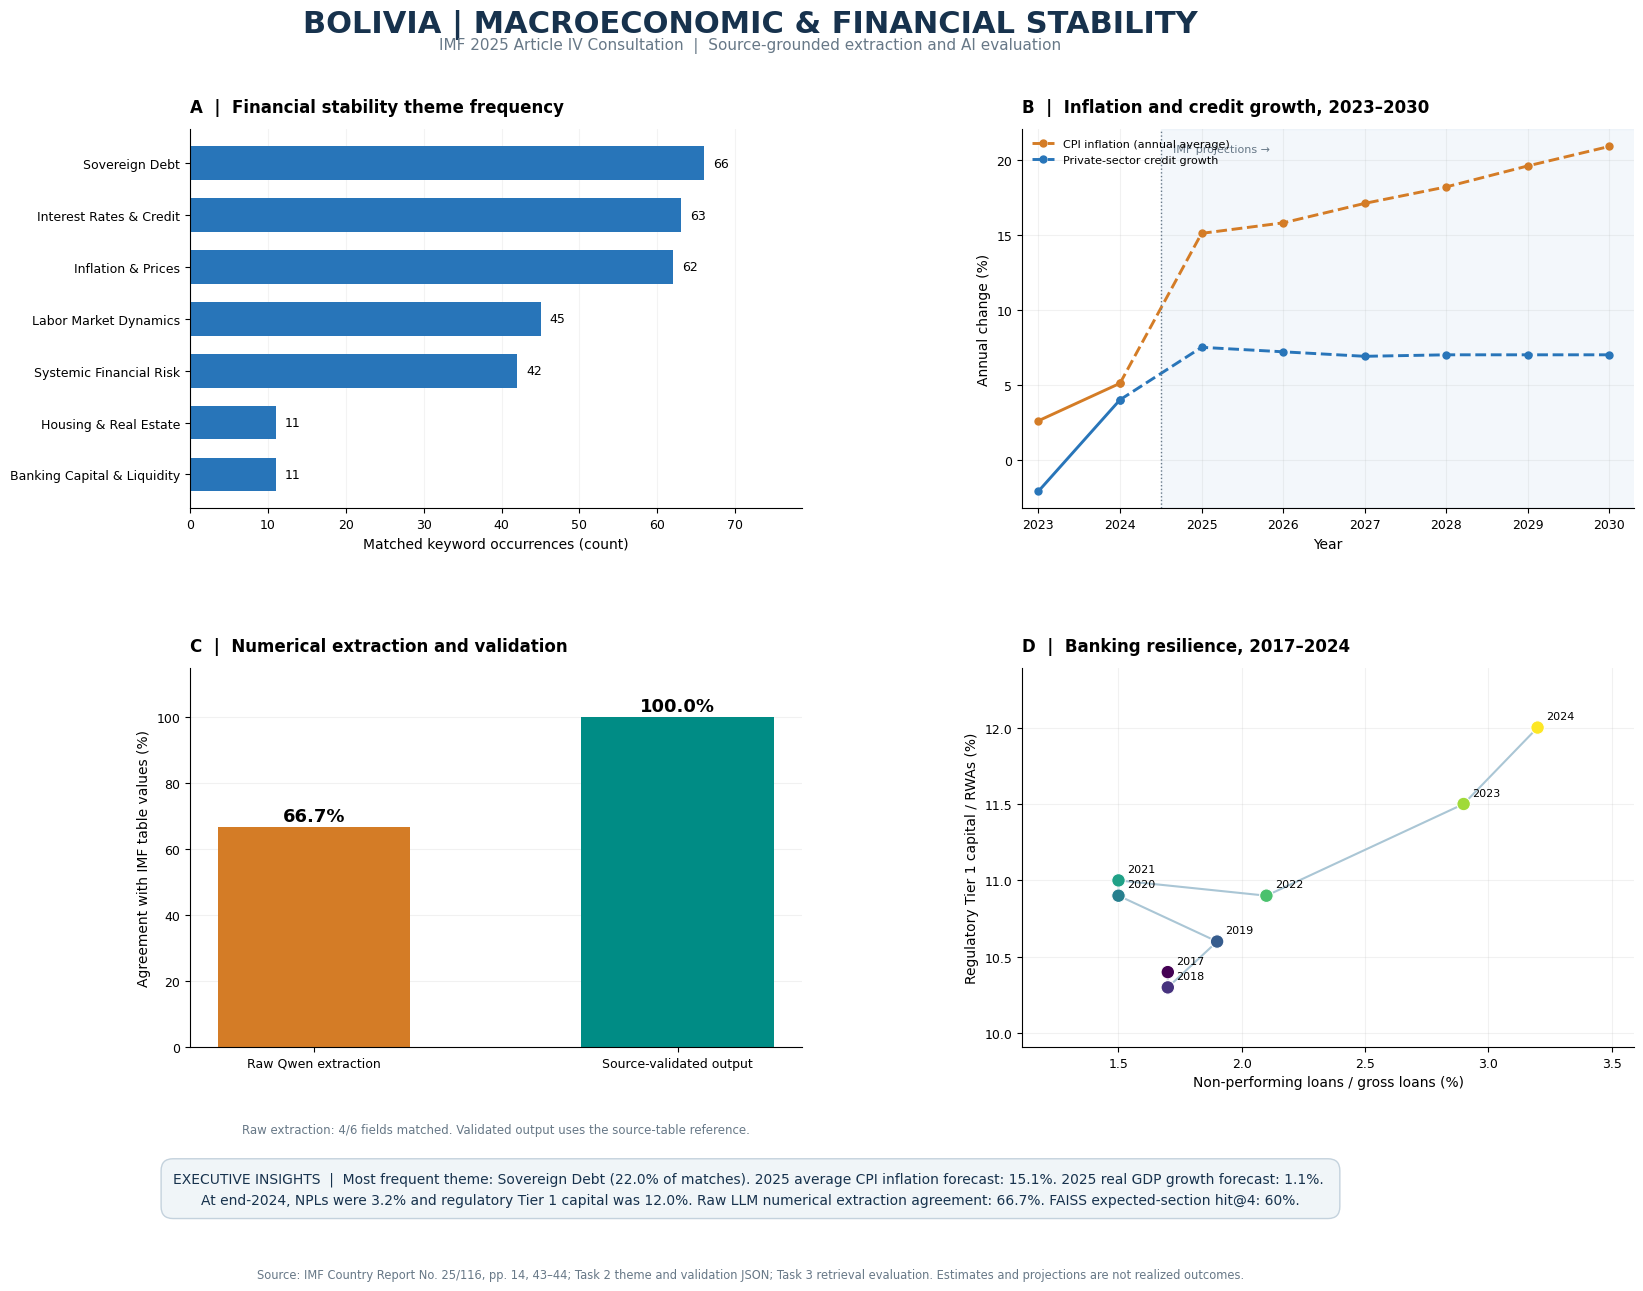


FOUR-PANEL DASHBOARD GENERATED
PNG: /content/bolivia_imf/Bolivia_Executive_Dashboard.png
PDF: /content/bolivia_imf/Bolivia_Executive_Dashboard.pdf
SVG: /content/bolivia_imf/Bolivia_Executive_Dashboard.svg


In [7]:

# TASK 4 — FOUR-PANEL EXECUTIVE DASHBOARD

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white"
})

NAVY = "#17324D"
BLUE = "#2875B9"
TEAL = "#008C85"
ORANGE = "#D47C26"
GRAY = "#677887"

fig, axes = plt.subplots(2, 2, figsize=(19, 13.5))
fig.patch.set_facecolor("white")

fig.suptitle(
    "BOLIVIA | MACROECONOMIC & FINANCIAL STABILITY",
    fontsize=22, fontweight="bold", color=NAVY, y=0.974
)
fig.text(
    0.5, 0.944,
    "IMF 2025 Article IV Consultation  |  "
    "Source-grounded extraction and AI evaluation",
    ha="center", fontsize=11, color=GRAY
)

# ------------------------------------------------------------
# PANEL A: THE SEVEN FINANCIAL THEMES
# ------------------------------------------------------------

ax = axes[0, 0]
plot_themes = theme_df.sort_values("Occurrences")

bars = ax.barh(
    plot_themes["Theme"],
    plot_themes["Occurrences"],
    color=BLUE,
    height=0.65
)

max_count = float(plot_themes["Occurrences"].max())
ax.set_xlim(0, max_count * 1.19)

for bar, value in zip(bars, plot_themes["Occurrences"]):
    ax.text(
        bar.get_width() + max_count * 0.018,
        bar.get_y() + bar.get_height()/2,
        str(int(value)), va="center", fontsize=9
    )

ax.set_title("A  |  Financial stability theme frequency", loc="left", pad=12)
ax.set_xlabel("Matched keyword occurrences (count)")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# PANEL B: INFLATION AND PRIVATE-SECTOR CREDIT GROWTH
# ------------------------------------------------------------

ax = axes[0, 1]
plot_series = {
    "CPI inflation (annual average)": (inflation, ORANGE),
    "Private-sector credit growth": (credit, BLUE)
}

ax.axvspan(
    2024.5, 2030.4, color=BLUE, alpha=0.055, zorder=0
)

for label, (series, color) in plot_series.items():
    x_hist = [2023, 2024]
    y_hist = [series[y] for y in x_hist]
    x_proj = list(range(2024, 2031))
    y_proj = [series[y] for y in x_proj]

    ax.plot(
        x_hist, y_hist, marker="o", linewidth=2.1,
        color=color, markersize=5
    )
    ax.plot(
        x_proj, y_proj, marker="o", linestyle="--",
        linewidth=2.1, markersize=5,
        color=color, label=label
    )

ax.axvline(2024.5, linestyle=":", linewidth=1, color=GRAY)
ax.text(
    2024.65, 0.96,
    "IMF projections →",
    transform=ax.get_xaxis_transform(),
    fontsize=8, color=GRAY, va="top"
)

ax.set_xlim(2022.8, 2030.3)
ax.set_xticks(economic_years)
ax.set_ylabel("Annual change (%)")
ax.set_xlabel("Year")
ax.set_title(
    "B  |  Inflation and credit growth, 2023–2030",
    loc="left", pad=12
)
ax.legend(loc="upper left", fontsize=8, frameon=False)
ax.grid(alpha=0.17)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# PANEL C: MODEL EXTRACTION DIAGNOSTIC
# ------------------------------------------------------------

ax = axes[1, 0]

agreement = task2_eval["source_agreement"]
matched = int(agreement["matched_fields"])
total = int(agreement["total_fields"])

if not 0 <= matched <= total or total == 0:
    raise ValueError("Invalid Task 2 extraction comparison.")

baseline_pct = 100 * matched / total

diagnostic_labels = [
    "Raw Qwen extraction",
    "Source-validated output"
]
diagnostic_values = [baseline_pct, 100.0]

bars = ax.bar(
    diagnostic_labels, diagnostic_values,
    color=[ORANGE, TEAL], width=0.53
)

for bar, value in zip(bars, diagnostic_values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center", fontweight="bold", fontsize=13
    )

ax.set_ylim(0, 115)
ax.set_ylabel("Agreement with IMF table values (%)")
ax.set_title(
    "C  |  Numerical extraction and validation",
    loc="left", pad=12
)
ax.grid(axis="y", alpha=0.17)
ax.set_axisbelow(True)

ax.text(
    0.5, -0.20,
    f"Raw extraction: {matched}/{total} fields matched. "
    "Validated output uses the source-table reference.",
    transform=ax.transAxes,
    ha="center", va="top", fontsize=8.5,
    color=GRAY, wrap=True
)

# ------------------------------------------------------------
# PANEL D: BANK CAPITAL VERSUS NON-PERFORMING LOANS
# ------------------------------------------------------------

ax = axes[1, 1]
x = bank_wide["Non-performing loan ratio"].to_numpy()
y = bank_wide["Tier 1 capital ratio"].to_numpy()
years = bank_wide["Year"].to_numpy()

ax.plot(
    x, y, linestyle="-", color="#AAC6D5",
    linewidth=1.5, zorder=1
)

points = ax.scatter(
    x, y, c=years, cmap="viridis",
    s=95, edgecolor="white", linewidth=0.8, zorder=3
)

for xi, yi, year in zip(x, y, years):
    ax.annotate(
        str(year), (xi, yi),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

ax.margins(x=0.23, y=0.23)
ax.set_xlabel("Non-performing loans / gross loans (%)")
ax.set_ylabel("Regulatory Tier 1 capital / RWAs (%)")
ax.set_title(
    "D  |  Banking resilience, 2017–2024",
    loc="left", pad=12
)
ax.grid(alpha=0.17)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# EXECUTIVE INSIGHT OVERLAY
# ------------------------------------------------------------

leading_theme = theme_df.loc[
    theme_df["Occurrences"].idxmax()
]

insights = (
    f"EXECUTIVE INSIGHTS  |  "
    f"Most frequent theme: {leading_theme['Theme']} "
    f"({leading_theme['Share_pct']:.1f}% of matches). "
    f"2025 average CPI inflation forecast: {inflation[2025]:.1f}%. "
    f"2025 real GDP growth forecast: {gdp[2025]:.1f}%. \n"
    f"At end-2024, NPLs were {npl[2024]:.1f}% and regulatory "
    f"Tier 1 capital was {tier1[2024]:.1f}%. "
    f"Raw LLM numerical extraction agreement: {baseline_pct:.1f}%. "
    f"FAISS expected-section hit@4: "
    f"{task3_eval['summary']['retrieval_hit_at_4_pct']:.0f}%."
)

fig.text(
    0.5, 0.100, insights,
    ha="center", va="center",
    fontsize=10, color=NAVY, linespacing=1.65,
    bbox={
        "boxstyle": "round,pad=0.85",
        "facecolor": "#F0F5F8",
        "edgecolor": "#C4D2DD"
    }
)

fig.text(
    0.5, 0.034,
    "Source: IMF Country Report No. 25/116, pp. 14, 43–44; "
    "Task 2 theme and validation JSON; Task 3 retrieval evaluation. "
    "Estimates and projections are not realized outcomes.",
    ha="center", fontsize=8.3, color=GRAY
)

# Reserve dedicated space for the header, plot labels and overlay.
fig.subplots_adjust(
    left=0.205,
    right=0.965,
    top=0.885,
    bottom=0.205,
    wspace=0.36,
    hspace=0.42
)

# Save publication-quality images.
DASHBOARD_PNG = BASE / "Bolivia_Executive_Dashboard.png"
DASHBOARD_PDF = BASE / "Bolivia_Executive_Dashboard.pdf"
DASHBOARD_SVG = BASE / "Bolivia_Executive_Dashboard.svg"

fig.savefig(DASHBOARD_PNG, dpi=300, facecolor="white")
fig.savefig(DASHBOARD_PDF, facecolor="white")
fig.savefig(DASHBOARD_SVG, facecolor="white")

plt.show()
plt.close(fig)

print("\nFOUR-PANEL DASHBOARD GENERATED")
print("PNG:", DASHBOARD_PNG)
print("PDF:", DASHBOARD_PDF)
print("SVG:", DASHBOARD_SVG)


In [8]:

# TASK 4 — FINAL VALIDATION AND EXPORT

import json
from pathlib import Path
from PIL import Image

# Check four required plot datasets.
checks = {
    "Seven financial themes": len(theme_df) == 7,
    "Long-format transformation": len(macro_long) == 24,
    "Inflation time series": len(inflation) == 8,
    "Credit growth time series": len(credit) == 8,
    "Tier 1 capital series": len(tier1) == 8,
    "NPL time series": len(npl) == 8,
    "Task 2 model comparison": total == 6,
    "2025 GDP forecast": np.isclose(gdp[2025], 1.1),
    "2024 NPL ratio": np.isclose(npl[2024], 3.2),
    "2024 Tier 1 ratio": np.isclose(tier1[2024], 12.0),
    "No missing plotting values": (
        macro_long["Value_pct"].notna().all()
        and bank_long["Value_pct"].notna().all()
    )
}

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {check}")

if not all(checks.values()):
    raise ValueError("One or more dashboard validation checks failed.")

# Validate output files.
for path in (DASHBOARD_PNG, DASHBOARD_PDF, DASHBOARD_SVG):
    assert path.exists() and path.stat().st_size > 0
    print(f"Verified: {path.name}")

with Image.open(DASHBOARD_PNG) as im:
    dimensions = im.size

assert dimensions[0] >= 4000
assert dimensions[1] >= 3000

dashboard_metadata = {
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "dashboard_panels": [
        {
            "panel": "A",
            "chart": "Seven-theme frequency",
            "source": "task2_themes.json",
            "unit": "Keyword occurrences"
        },
        {
            "panel": "B",
            "chart": "Inflation and private credit growth",
            "source_pages": [14, 43],
            "years": economic_years,
            "unit": "Percent"
        },
        {
            "panel": "C",
            "chart": "Raw LLM versus source-validated extraction",
            "source": "task2_evaluation.json",
            "raw_agreement_pct": round(baseline_pct, 2),
            "matched_fields": matched,
            "total_fields": total
        },
        {
            "panel": "D",
            "chart": "Tier 1 bank capital versus NPLs",
            "source_page": 44,
            "years": banking_years,
            "unit": "Percent"
        }
    ],
    "executive_indicators": {
        "gdp_growth_2025_forecast_pct": gdp[2025],
        "cpi_inflation_2025_average_forecast_pct": inflation[2025],
        "npl_ratio_2024_pct": npl[2024],
        "tier1_capital_2024_pct": tier1[2024]
    },
    "output_files": {
        "png": DASHBOARD_PNG.name,
        "pdf": DASHBOARD_PDF.name,
        "svg": DASHBOARD_SVG.name,
        "macro_long": "task4_macro_long.csv",
        "bank_long": "task4_banking_long.csv"
    },
    "png_dimensions": list(dimensions),
    "limitations": [
        "Theme frequencies describe textual emphasis, not risk severity.",
        "The original report lacks an unambiguous policy-rate series.",
        "Financial-sector comparison uses Tier 1 capital and NPLs.",
        "Raw LLM agreement is measured against parsed IMF source tables.",
        "The validated output agrees with its own source-table reference.",
        "2025-2030 economic projections are not realized outcomes."
    ]
}

metadata_path = BASE / "task4_dashboard_metadata.json"
metadata_path.write_text(
    json.dumps(
        dashboard_metadata,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\n" + "=" * 55)
print("TASK 4 COMPLETED SUCCESSFULLY")
print("=" * 55)
print("Dashboard: 4 panels")
print("Resolution:", dimensions[0], "x", dimensions[1])
print("Tidy transformation: pd.melt() completed")
print("Missing values handled")
print("Figure exports: PNG, PDF, SVG")
print("Saved folder:", BASE)


PASS | Seven financial themes
PASS | Long-format transformation
PASS | Inflation time series
PASS | Credit growth time series
PASS | Tier 1 capital series
PASS | NPL time series
PASS | Task 2 model comparison
PASS | 2025 GDP forecast
PASS | 2024 NPL ratio
PASS | 2024 Tier 1 ratio
PASS | No missing plotting values
Verified: Bolivia_Executive_Dashboard.png
Verified: Bolivia_Executive_Dashboard.pdf
Verified: Bolivia_Executive_Dashboard.svg

TASK 4 COMPLETED SUCCESSFULLY
Dashboard: 4 panels
Resolution: 5700 x 4050
Tidy transformation: pd.melt() completed
Missing values handled
Figure exports: PNG, PDF, SVG
Saved folder: /content/bolivia_imf


Multi-query RAG 1/5: What improvements did the IMF recommend for Bolivia's bank capital buffers and financial supervision?
Multi-query RAG 2/5: What are the IMF recommendations for bank solvency stress testing and systemic risk monitoring?
Multi-query RAG 3/5: What monetary framework and inflation targeting transition did IMF staff recommend for Bolivia?
Multi-query RAG 4/5: Why does the IMF assess Bolivia's near-term sovereign debt distress risk as high?
Multi-query RAG 5/5: What financial vulnerabilities arise from foreign exchange shortages and deposit outflows?


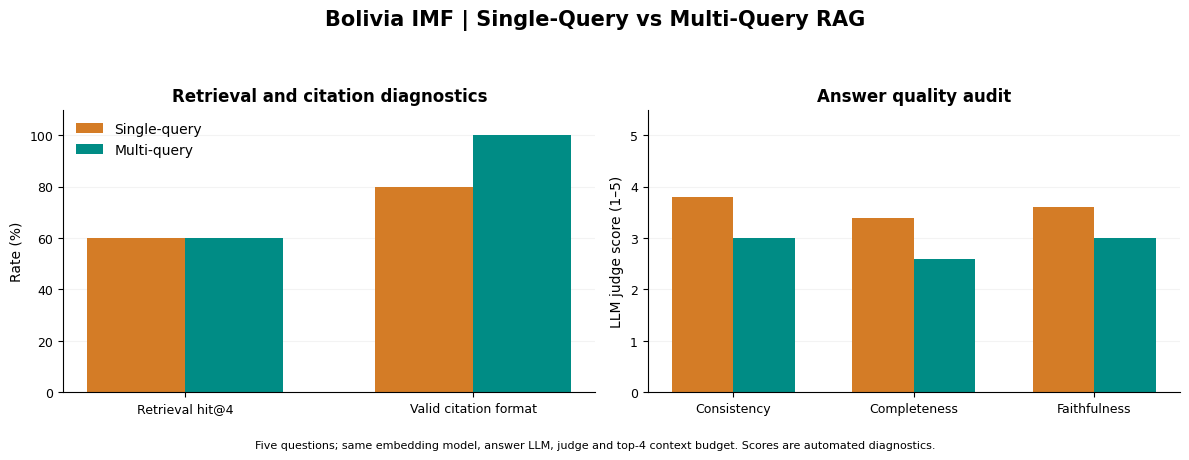


EXTRA CREDIT — MULTI-QUERY RAG BENCHMARK
Original test questions: 5
Original indexed passages: 374
Query variations per question: 4
Retrieved passages per answer: 4

BASELINE vs MULTI-QUERY
retrieval_hit_at_4_pct: 60.0 -> 60.0 (change: 0.0)
citation_format_valid_pct: 80.0 -> 100.0 (change: 20.0)
consistency_out_of_5: 3.8 -> 3.0 (change: -0.8)
completeness_out_of_5: 3.4 -> 2.6 (change: -0.8)
faithfulness_out_of_5: 3.6 -> 3.0 (change: -0.6)

PER-QUESTION COMPARISON


,question_id,question,baseline_hit4,multi_hit4,baseline_citation_valid,multi_citation_valid,baseline_consistency,multi_consistency,baseline_completeness,multi_completeness,baseline_faithfulness,multi_faithfulness
0,1,What improvements did the IMF recommend for Bo...,0,0,0,1,3,3,2,2,3,2
1,2,What are the IMF recommendations for bank solv...,1,1,1,1,5,3,5,3,5,4
2,3,What monetary framework and inflation targetin...,0,0,1,1,3,3,2,2,2,2
3,4,Why does the IMF assess Bolivia's near-term so...,1,1,1,1,3,3,3,3,3,3
4,5,What financial vulnerabilities arise from fore...,1,1,1,1,5,3,5,3,5,4



Saved: /content/bolivia_imf/extra_multiquery_results.json
Saved: /content/bolivia_imf/extra_multiquery_comparison.csv
Saved: /content/bolivia_imf/Extra_MultiQuery_RAG_Comparison.png

EXTRA-CREDIT EVALUATION FINISHED


In [9]:

# ============================================================
# MULTI-QUERY RAG vs BASELINE SINGLE-QUERY RAG
# Bolivia IMF 2025 Article IV Consultation
# Local MiniLM + FAISS + Qwen3-4B; no API key.
# ============================================================

import json, re, hashlib, time
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/content/bolivia_imf")
VERSION = "multiquery_rrf_v1"
OUT = BASE / "extra_multiquery_results.json"
CSV = BASE / "extra_multiquery_comparison.csv"

# ------------------------------------------------------------
# 1. RESTORE BASELINE AND CHECK EXISTING COMPONENTS
# ------------------------------------------------------------

required = ["embedder", "index", "passages", "cached_generate"]
missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(
        f"Missing runtime components: {missing}. "
        "Run the model setup and FAISS indexing cells first."
    )

baseline_file = BASE / "task3_rag_answers.json"
baseline_eval_file = BASE / "task3_evaluation.json"

if not baseline_file.exists() or not baseline_eval_file.exists():
    raise FileNotFoundError(
        "Task 3 baseline files missing. Restore Task 3 outputs."
    )

baseline = json.loads(baseline_file.read_text(encoding="utf-8"))
baseline_eval = json.loads(
    baseline_eval_file.read_text(encoding="utf-8")
)
baseline_judges = baseline_eval["evaluations"]

questions = list(baseline.keys())
assert len(questions) == 5, "Expected five original RAG questions."
assert all(q in baseline_judges for q in questions)
assert index.ntotal == len(passages)

# Report-specific relevance ranges, used ONLY for evaluation,
# never to insert passages into retrieval results.
EXPECTED_RANGES = [
    [(23, 25), (61, 62)],
    [(23, 25), (61, 62)],
    [(15, 17)],
    [(13, 14), (48, 56)],
    [(11, 17), (23, 25)]
]

# ------------------------------------------------------------
# 2. PROGRAMMATIC QUERY VARIATIONS
# ------------------------------------------------------------

# Domain-specific vocabulary expansion.
# These are search terms, not hardcoded answers or source text.
SYNONYMS = [
    (r"capital buffers?", "capital adequacy macroprudential buffers"),
    (r"financial supervision", "bank supervision prudential regulation"),
    (r"solvency stress testing", "bank solvency stress tests FSAP"),
    (r"stress testing", "stress tests financial sector assessment"),
    (r"systemic risk monitoring", "financial stability council systemic risk"),
    (r"inflation targeting", "base money target monetary framework inflation targeting"),
    (r"monetary framework", "exchange rate flexibility monetary policy framework"),
    (r"sovereign debt distress", "sovereign risk debt sustainability SRDSF"),
    (r"foreign exchange shortages", "FX scarcity reserve depletion"),
    (r"deposit outflows", "bank deposits capital outflows FX liquidity")
]

def generate_query_variations(question):
    """Create multiple semantic search formulations in Python."""
    question = re.sub(r"\s+", " ", question).strip()
    core = question.rstrip(" ?.")

    expanded = core
    for pattern, replacement in SYNONYMS:
        expanded = re.sub(
            pattern, replacement, expanded, flags=re.I
        )

    variations = [
        question,
        f"Bolivia 2025 IMF Article IV staff recommendations: {core}",
        f"IMF Bolivia financial stability assessment: {expanded}",
        f"Report evidence, risks, policy measures and timeline: {expanded}"
    ]

    # Preserve query order while eliminating exact duplicates.
    return list(dict.fromkeys(variations))

# ------------------------------------------------------------
# 3. FAISS MULTI-QUERY RETRIEVAL + RANK FUSION
# ------------------------------------------------------------

def search_one_query(query, k=8):
    vector = embedder.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    distances, ids = index.search(
        np.ascontiguousarray(vector),
        min(k, index.ntotal)
    )

    return [
        (int(idx), float(dist), rank)
        for rank, (idx, dist) in enumerate(
            zip(ids[0], distances[0]), 1
        )
        if idx >= 0
    ]

def multiquery_retrieve(question, top_k=4):
    """
    Weighted Reciprocal Rank Fusion.
    Original query receives slightly greater weight.
    Near-duplicate passages from the same original chunk
    are restricted to improve evidence diversity.
    """
    variations = generate_query_variations(question)
    scores = defaultdict(float)
    best_distances = {}
    matched_queries = defaultdict(set)

    for qi, query in enumerate(variations):
        weight = 1.3 if qi == 0 else 1.0

        for idx, distance, rank in search_one_query(query, k=8):
            scores[idx] += weight / (60 + rank)
            matched_queries[idx].add(qi)
            best_distances[idx] = min(
                distance,
                best_distances.get(idx, float("inf"))
            )

    ranked = sorted(
        scores, key=lambda i: (-scores[i], best_distances[i])
    )

    chosen = []
    used_chunks = set()

    for idx in ranked:
        passage = passages[idx]
        chunk_id = passage["source_chunk_id"]

        if chunk_id in used_chunks:
            continue

        chosen.append(idx)
        used_chunks.add(chunk_id)

        if len(chosen) == top_k:
            break

    # Fallback if diversity filtering returns fewer than k.
    for idx in ranked:
        if len(chosen) >= top_k:
            break
        if idx not in chosen:
            chosen.append(idx)

    results = []
    for rank, idx in enumerate(chosen, 1):
        p = passages[idx]
        results.append({
            "rank": rank,
            "passage_id": int(p["id"]),
            "source_chunk_id": p["source_chunk_id"],
            "page_start": int(p["page_start"]),
            "page_end": int(p["page_end"]),
            "l2_distance": round(best_distances[idx], 5),
            "rrf_score": round(scores[idx], 7),
            "query_coverage": len(matched_queries[idx]),
            "text": p["text"]
        })

    return variations, results

# ------------------------------------------------------------
# 4. GENERATE GROUNDED ANSWERS WITH THE EXISTING QWEN MODEL
# ------------------------------------------------------------

# Reuse the Task 3 grounding instructions for comparability.
GROUNDING_PROMPT = globals().get("RAG_SYSTEM", """
You are an IMF document-based financial research assistant.
Answer using ONLY the supplied retrieved passages.
Distinguish IMF staff from authorities' views.
Preserve exact figures, dates, units and qualifications.
Cite factual claims using [S1], [S2], etc.
If evidence is insufficient, state that it is not established.
Do not invent numerical values or policy recommendations.
Keep answers concise and factual.
""")

def answer_multiquery(question):
    variations, hits = multiquery_retrieve(question, top_k=4)

    context = "\n\n".join(
        f"[S{i} | PDF pages {h['page_start']}-"
        f"{h['page_end']}]\n{h['text']}"
        for i, h in enumerate(hits, 1)
    )

    prompt = (
        f"QUESTION:\n{question}\n\n"
        f"RETRIEVED IMF SOURCE PASSAGES:\n{context}\n\n"
        "Answer using only these passages and cite their source IDs."
    )

    answer = cached_generate(
        GROUNDING_PROMPT,
        prompt,
        max_new_tokens=260,
        temperature=0.1
    )

    cited = [
        int(n) for n in re.findall(r"\[S(\d+)\]", answer)
    ]

    citation_valid = (
        bool(cited) and
        all(1 <= n <= len(hits) for n in cited)
    )

    return {
        "question": question,
        "query_variations": variations,
        "answer": answer,
        "retrieved_sources": hits,
        "citation_format_valid": citation_valid
    }

# ------------------------------------------------------------
# 5. REUSE THE SAME LLM-AS-A-JUDGE FRAMEWORK
# ------------------------------------------------------------

if "judge_rag_answer" not in globals():
    raise RuntimeError(
        "Task 3 judge_rag_answer() is not loaded. "
        "Run Cell 9 to define the evaluator before this cell."
    )

def section_hit(sources, ranges):
    """Check whether retrieved PDF pages overlap relevant sections."""
    return any(
        s["page_start"] <= end and s["page_end"] >= start
        for s in sources
        for start, end in ranges
    )

# Versioned checkpoint avoids unnecessary repeat inference.
# Include model/index identity to avoid stale benchmark reuse.
index_config_path = BASE / "task3_index_config.json"
index_config = (
    json.loads(index_config_path.read_text(encoding="utf-8"))
    if index_config_path.exists() else {}
)

fingerprint = hashlib.sha256(
    json.dumps({
        "version": VERSION,
        "questions": questions,
        "index": index_config.get("fingerprint"),
        "model": globals().get("MODEL_ID", "Qwen3-4B"),
        "grounding_prompt": GROUNDING_PROMPT
    }, sort_keys=True).encode()
).hexdigest()

if OUT.exists():
    saved = json.loads(OUT.read_text(encoding="utf-8"))
    results = (
        saved.get("results", {})
        if saved.get("fingerprint") == fingerprint else {}
    )
else:
    results = {}

for i, question in enumerate(questions, 1):
    if question not in results:
        print(f"Multi-query RAG {i}/{len(questions)}: {question}")

        enhanced = answer_multiquery(question)
        evaluation = judge_rag_answer(enhanced)

        results[question] = {
            "enhanced": enhanced,
            "evaluation": evaluation
        }

        OUT.write_text(
            json.dumps({
                "version": VERSION,
                "fingerprint": fingerprint,
                "results": results
            }, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )
    else:
        print(f"Reused benchmark {i}/{len(questions)}")

# ------------------------------------------------------------
# 6. FAIR BASELINE vs ENHANCED COMPARISON
# ------------------------------------------------------------

rows = []

for i, question in enumerate(questions):
    old = baseline[question]
    old_judge = baseline_judges[question]

    new = results[question]["enhanced"]
    new_judge = results[question]["evaluation"]

    ranges = EXPECTED_RANGES[i]

    baseline_hit = section_hit(
        old["retrieved_sources"], ranges
    )
    multi_hit = section_hit(
        new["retrieved_sources"], ranges
    )

    def citation_ok(item):
        cited = [
            int(x) for x in re.findall(
                r"\[S(\d+)\]", item["answer"]
            )
        ]
        return (
            bool(cited) and
            all(1 <= c <= len(item["retrieved_sources"])
                for c in cited)
        )

    rows.append({
        "question_id": i + 1,
        "question": question,
        "baseline_hit4": int(baseline_hit),
        "multi_hit4": int(multi_hit),
        "baseline_citation_valid": int(citation_ok(old)),
        "multi_citation_valid": int(citation_ok(new)),
        "baseline_consistency": old_judge.get("consistency"),
        "multi_consistency": new_judge.get("consistency"),
        "baseline_completeness": old_judge.get("completeness"),
        "multi_completeness": new_judge.get("completeness"),
        "baseline_faithfulness": old_judge.get("faithfulness"),
        "multi_faithfulness": new_judge.get("faithfulness")
    })

comparison = pd.DataFrame(rows)
comparison.to_csv(CSV, index=False)

def safe_mean(column):
    values = pd.to_numeric(
        comparison[column], errors="coerce"
    ).dropna()
    return round(float(values.mean()), 3) if len(values) else None

metrics = {
    "retrieval_hit_at_4_pct": {
        "baseline": 100 * safe_mean("baseline_hit4"),
        "multi_query": 100 * safe_mean("multi_hit4")
    },
    "citation_format_valid_pct": {
        "baseline": 100 * safe_mean("baseline_citation_valid"),
        "multi_query": 100 * safe_mean("multi_citation_valid")
    },
    "consistency_out_of_5": {
        "baseline": safe_mean("baseline_consistency"),
        "multi_query": safe_mean("multi_consistency")
    },
    "completeness_out_of_5": {
        "baseline": safe_mean("baseline_completeness"),
        "multi_query": safe_mean("multi_completeness")
    },
    "faithfulness_out_of_5": {
        "baseline": safe_mean("baseline_faithfulness"),
        "multi_query": safe_mean("multi_faithfulness")
    }
}

for data in metrics.values():
    a, b = data["baseline"], data["multi_query"]
    data["change"] = (
        round(b - a, 3)
        if a is not None and b is not None else None
    )

# ------------------------------------------------------------
# 7. SAVE BENCHMARK RESULTS AND VISUAL COMPARISON
# ------------------------------------------------------------

final_output = {
    "extension": "Enhanced Retrieval Strategy: Multi-Query RAG",
    "version": VERSION,
    "fingerprint": fingerprint,
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "embedding_model": globals().get(
        "EMBED_MODEL", "sentence-transformers/all-MiniLM-L6-v2"
    ),
    "vector_index": "FAISS IndexFlatL2",
    "method": "Python query variants + weighted reciprocal rank fusion",
    "questions": len(questions),
    "retrieval_top_k": 4,
    "metrics": metrics,
    "results": results,
    "limitations": [
        "Only five factual test questions were evaluated.",
        "Expected-section hit@4 uses predefined report page ranges.",
        "Same Qwen model generates and judges answers.",
        "Judge scores are not independently verified ground truth.",
        "Citation validity checks syntax, not factual entailment.",
        "Multiple query variations can introduce irrelevant context.",
        "Improvements cannot be assumed without measured evidence."
    ]
}

OUT.write_text(
    json.dumps(final_output, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Compact comparison chart for the written report.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ["Retrieval hit@4", "Valid citation format"]
base_retrieval = [
    metrics["retrieval_hit_at_4_pct"]["baseline"],
    metrics["citation_format_valid_pct"]["baseline"]
]
multi_retrieval = [
    metrics["retrieval_hit_at_4_pct"]["multi_query"],
    metrics["citation_format_valid_pct"]["multi_query"]
]

x = np.arange(len(labels))
width = 0.34

axes[0].bar(x-width/2, base_retrieval, width,
            label="Single-query", color="#D47C26")
axes[0].bar(x+width/2, multi_retrieval, width,
            label="Multi-query", color="#008C85")
axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 110)
axes[0].set_ylabel("Rate (%)")
axes[0].set_title("Retrieval and citation diagnostics")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.15)

judge_names = ["Consistency", "Completeness", "Faithfulness"]
judge_keys = [
    "consistency_out_of_5",
    "completeness_out_of_5",
    "faithfulness_out_of_5"
]

b = [metrics[k]["baseline"] for k in judge_keys]
m = [metrics[k]["multi_query"] for k in judge_keys]

x2 = np.arange(3)
axes[1].bar(x2-width/2, b, width,
            label="Single-query", color="#D47C26")
axes[1].bar(x2+width/2, m, width,
            label="Multi-query", color="#008C85")
axes[1].set_xticks(x2, judge_names)
axes[1].set_ylim(0, 5.5)
axes[1].set_ylabel("LLM judge score (1–5)")
axes[1].set_title("Answer quality audit")
axes[1].grid(axis="y", alpha=0.15)

for ax in axes:
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Bolivia IMF | Single-Query vs Multi-Query RAG",
    fontweight="bold", fontsize=15
)
fig.text(
    0.5, 0.005,
    "Five questions; same embedding model, answer LLM, judge and "
    "top-4 context budget. Scores are automated diagnostics.",
    ha="center", fontsize=8
)
fig.tight_layout(rect=[0, 0.045, 1, 0.92])

CHART = BASE / "Extra_MultiQuery_RAG_Comparison.png"
fig.savefig(CHART, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. FINAL OUTPUT
# ------------------------------------------------------------

assert len(results) == len(questions)
assert len(comparison) == 5
assert OUT.exists() and CSV.exists() and CHART.exists()

print("\n" + "="*60)
print("EXTRA CREDIT — MULTI-QUERY RAG BENCHMARK")
print("="*60)
print("Original test questions:", len(questions))
print("Original indexed passages:", index.ntotal)
print("Query variations per question: 4")
print("Retrieved passages per answer: 4")
print("\nBASELINE vs MULTI-QUERY")

for name, values in metrics.items():
    print(
        f"{name}: {values['baseline']} -> "
        f"{values['multi_query']} "
        f"(change: {values['change']})"
    )

print("\nPER-QUESTION COMPARISON")
display(comparison)

print("\nSaved:", OUT)
print("Saved:", CSV)
print("Saved:", CHART)
print("\nEXTRA-CREDIT EVALUATION FINISHED")


In [10]:

# ============================================================
# CELL 14 — FINAL VALIDATION AND SUBMISSION PACKAGING
# Bolivia IMF 2025 | Tasks 1–4 + Extra Credit
# No LLM inference or API key required.
# ============================================================

import json, re, math, zipfile, hashlib
from pathlib import Path
from PIL import Image
from IPython.display import display
import pandas as pd

BASE = Path("/content/bolivia_imf")
assert BASE.is_dir(), "Output folder missing. Restore saved results."

checks, warnings_list = [], []

def check(name, condition, detail=""):
    checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": str(detail)
    })

def load_json(name, required=True):
    path = BASE / name
    if not path.is_file():
        if required:
            warnings_list.append(f"Missing: {name}")
        return None
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (ValueError, UnicodeDecodeError) as e:
        warnings_list.append(f"Invalid JSON: {name} ({e})")
        return None

def word_count(text):
    return len(re.findall(r"\b[\w'-]+\b", str(text)))

# ------------------------------------------------------------
# TASK 1: PDF PROCESSING, SUMMARIES AND EVALUATION
# ------------------------------------------------------------

chunks = load_json("chunks.json")
summaries = load_json("section_summaries.json")
task1_eval = load_json("task1_evaluation.json")

# Support both Task 1 summary formats used in the notebook.
if summaries and "summaries" in summaries:
    summaries = summaries["summaries"]

# Support a consolidated or direct evaluation dictionary.
if task1_eval and "evaluations" in task1_eval:
    task1_eval = task1_eval["evaluations"]

if chunks:
    check("T1: PDF chunks", len(chunks) > 0, len(chunks))
    check(
        "T1: Chunk size <= 420 tokens",
        all(
            int(c.get("token_count", 0)) <= 420
            and int(c.get("token_count", 0)) > 0
            for c in chunks
        )
    )
else:
    check("T1: PDF chunks", False)

check(
    "T1: Cleaned source text",
    (BASE / "cleaned_text.txt").is_file()
    and (BASE / "cleaned_text.txt").stat().st_size > 0
    if (BASE / "cleaned_text.txt").exists() else False
)

if isinstance(summaries, dict) and summaries:
    summary_lengths = {
        name: word_count(item.get("summary", ""))
        for name, item in summaries.items()
    }
    check(
        "T1: Section summaries exist",
        len(summaries) >= 20,
        f"{len(summaries)} sections"
    )
    check(
        "T1: All summaries under 100 words",
        all(0 < count < 100 for count in summary_lengths.values()),
        f"Maximum: {max(summary_lengths.values())} words"
    )
else:
    check("T1: Section summaries", False)

if isinstance(task1_eval, dict):
    evaluated_sections = [
        name for name in (summaries or {})
        if name in task1_eval
    ]
    check(
        "T1: Section evaluation coverage",
        len(evaluated_sections) == len(summaries or {}),
        f"{len(evaluated_sections)}/{len(summaries or {})}"
    )
    check(
        "T1: Executive summary evaluation",
        "Executive Summary" in task1_eval
    )
    failed_judges = [
        name for name, result in task1_eval.items()
        if not isinstance(result, dict)
        or any(
            result.get(metric) is None
            for metric in ("consistency", "completeness", "faithfulness")
        )
    ]
    check(
        "T1: Judge scores available",
        len(failed_judges) == 0,
        f"{len(failed_judges)} missing/invalid scores"
    )
else:
    check("T1: Evaluations", False)

check(
    "T1: Executive summary saved",
    (BASE / "executive_summary.txt").is_file()
)

# ------------------------------------------------------------
# TASK 2: THEMES, JSON SCHEMA AND FALLBACKS
# ------------------------------------------------------------

indicators = load_json("task2_indicators.json")
themes = load_json("task2_themes.json")
qualitative = load_json("task2_qualitative.json")
fallbacks = load_json("task2_fallbacks.json")
trends = load_json("task2_trends.json")
task2_eval = load_json("task2_evaluation.json")

required_fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

if isinstance(indicators, dict):
    schema_ok = set(indicators) == set(required_fields)
    types_ok = (
        isinstance(indicators.get("country_name"), str)
        and all(
            v is None or (
                isinstance(v, (int, float))
                and not isinstance(v, bool)
                and math.isfinite(v)
            )
            for k, v in indicators.items()
            if k != "country_name"
        )
    )
    check("T2: Exact seven-field schema", schema_ok)
    check("T2: Valid indicator types", types_ok)

    # Independently check key reported numbers.
    reference = {
        "gdp_growth_forecast_pct": 1.1,
        "headline_inflation_rate_pct": 15.6,
        "non_performing_loan_ratio": 3.2,
        "unemployment_rate_pct": 3.6,
        "tier_1_capital_ratio": 12.0
    }
    for field, expected in reference.items():
        actual = indicators.get(field)
        check(
            f"T2: {field}",
            isinstance(actual, (int, float))
            and not isinstance(actual, bool)
            and math.isclose(float(actual), expected, abs_tol=0.01),
            f"Expected {expected}; found {actual}"
        )
    check(
        "T2: Missing policy-rate fallback",
        indicators.get("central_bank_policy_rate_pct") is None
    )
else:
    check("T2: Core indicator JSON", False)

check(
    "T2: Seven thematic categories",
    isinstance(themes, dict)
    and isinstance(themes.get("themes"), dict)
    and len(themes["themes"]) == 7
)

if isinstance(qualitative, dict):
    strengths = qualitative.get("strengths", [])
    vulnerabilities = qualitative.get("vulnerabilities", [])
    check(
        "T2: 5–7 economic strengths",
        5 <= len(strengths) <= 7,
        len(strengths)
    )
    check(
        "T2: 5–7 vulnerabilities",
        5 <= len(vulnerabilities) <= 7,
        len(vulnerabilities)
    )
else:
    check("T2: Qualitative insights", False)

check(
    "T2: Fallback explanation saved",
    isinstance(fallbacks, dict)
    and "central_bank_policy_rate_pct" in fallbacks
    and bool(fallbacks["central_bank_policy_rate_pct"].get("reason"))
)

check(
    "T2: Historical and projected trends",
    isinstance(trends, dict)
    and any(
        isinstance(item, dict)
        and len(item.get("observations", [])) >= 2
        for item in trends.values()
    )
)

check(
    "T2: Evaluation saved",
    isinstance(task2_eval, dict)
    and "indicator_judge" in task2_eval
    and "qualitative_judge" in task2_eval
)

# ------------------------------------------------------------
# TASK 3: FAISS RAG AND EVALUATION
# ------------------------------------------------------------

rag = load_json("task3_results.json")
rag_eval = load_json("task3_evaluation.json")
rag_passages = load_json("task3_passages.json")

index_path = BASE / "task3_faiss.index"

check(
    "T3: FAISS index saved",
    index_path.is_file() and index_path.stat().st_size > 0
    if index_path.exists() else False
)

check(
    "T3: Indexed source passages",
    isinstance(rag_passages, list) and len(rag_passages) > 0,
    f"{len(rag_passages) if isinstance(rag_passages, list) else 0} passages"
)

check(
    "T3: Five grounded answers",
    isinstance(rag, dict)
    and len(rag.get("questions_and_answers", [])) == 5
)

check(
    "T3: RAG evaluation",
    isinstance(rag_eval, dict)
    and "summary" in rag_eval
    and "evaluations" in rag_eval
    and len(rag_eval["evaluations"]) == 5
)

# Inspect saved index metadata without loading the embedding model.
try:
    import faiss
    if index_path.exists():
        saved_index = faiss.read_index(str(index_path))
        check(
            "T3: Genuine 384-dimension FAISS index",
            saved_index.d == 384
            and saved_index.ntotal == len(rag_passages or []),
            f"{saved_index.ntotal} vectors"
        )
except ImportError:
    warnings_list.append(
        "FAISS import unavailable: index file exists but contents "
        "were not independently inspected."
    )

# ------------------------------------------------------------
# TASK 4: DASHBOARD, DATA AND EXPORTS
# ------------------------------------------------------------

dashboard_files = [
    BASE / "Bolivia_Executive_Dashboard.png",
    BASE / "Bolivia_Executive_Dashboard.pdf",
    BASE / "Bolivia_Executive_Dashboard.svg"
]

for path in dashboard_files:
    check(
        f"T4: {path.suffix.upper()} export",
        path.is_file() and path.stat().st_size > 0
        if path.exists() else False
    )

png_path = dashboard_files[0]
if png_path.exists():
    with Image.open(png_path) as img:
        width, height = img.size
    check(
        "T4: High-resolution dashboard",
        width >= 4000 and height >= 3000,
        f"{width} x {height}"
    )

macro_csv = BASE / "task4_macro_long.csv"
bank_csv = BASE / "task4_banking_long.csv"

if macro_csv.exists():
    macro_df = pd.read_csv(macro_csv)
    check(
        "T4: Long-format macro dataset",
        {"Year", "Indicator", "Value_pct"}.issubset(macro_df.columns)
        and len(macro_df) >= 16
    )
else:
    check("T4: Long-format macro dataset", False)

check(
    "T4: Long-format banking dataset",
    bank_csv.exists() and bank_csv.stat().st_size > 0
    if bank_csv.exists() else False
)

check(
    "T4: Dashboard metadata",
    (BASE / "task4_dashboard_metadata.json").exists()
)

# ------------------------------------------------------------
# EXTRA CREDIT: MULTI-QUERY RAG
# ------------------------------------------------------------

extra = load_json("extra_multiquery_results.json")

if isinstance(extra, dict):
    metrics = extra.get("metrics", {})
    check(
        "EXTRA: Multi-query benchmark",
        len(metrics) >= 5
        and "faithfulness_out_of_5" in metrics
        and "completeness_out_of_5" in metrics
    )
    check(
        "EXTRA: Five question comparisons",
        len(extra.get("results", {})) == 5
    )
else:
    check("EXTRA: Benchmark", False)

check(
    "EXTRA: Comparison figure",
    (BASE / "Extra_MultiQuery_RAG_Comparison.png").exists()
)

# ------------------------------------------------------------
# FINAL QUALITY AND FILE SECURITY AUDIT
# ------------------------------------------------------------

# Report limitations still requiring human review.
review_notes = [
    "Task 1 summaries require final factual review; generated "
    "text may contain unsupported numerical interpretations.",
    "Task 2 raw Qwen extraction selected incorrect forecast-year "
    "values for two fields; final validated JSON uses source tables.",
    "Task 3 baseline retrieval hit@4 was 60%, indicating limited "
    "retrieval reliability on the five evaluated questions.",
    "Multi-query RAG did not improve completeness or faithfulness.",
    "The same lightweight LLM was used for generation and judging.",
    "A saved-output check does not prove fresh-runtime reproducibility."
]

# Files that should never be packaged.
EXCLUDE_NAMES = {
    ".env", "credentials.json", "token.json",
    "secrets.json", "api_key.txt"
}
EXCLUDE_DIRS = {"cache", "__pycache__", ".ipynb_checkpoints"}

def include_file(path):
    relative_parts = path.relative_to(BASE).parts
    if any(part in EXCLUDE_DIRS for part in relative_parts[:-1]):
        return False
    if path.name.lower() in EXCLUDE_NAMES:
        return False
    if path.suffix.lower() not in {
        ".json", ".txt", ".csv", ".png", ".pdf",
        ".svg", ".index"
    }:
        return False
    return True

status_df = pd.DataFrame(checks)
display(status_df)

passed = sum(x["Status"] == "PASS" for x in checks)
failed = [x for x in checks if x["Status"] == "FAIL"]

audit = {
    "country": "Bolivia",
    "report": "IMF Country Report No. 25/116",
    "checks_passed": passed,
    "checks_total": len(checks),
    "failed_checks": failed,
    "warnings": warnings_list,
    "human_review_notes": review_notes,
    "validation_checks": checks
}

audit_path = BASE / "final_validation_audit.json"
audit_path.write_text(
    json.dumps(audit, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Package reproducible outputs. Exclude caches and credentials.
zip_path = Path("/content/Bolivia_IMF_Assessment_Outputs.zip")
files_to_zip = [
    p for p in BASE.rglob("*")
    if p.is_file() and include_file(p)
]

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for file in files_to_zip:
        archive.write(
            file, arcname=str(file.relative_to(BASE))
        )

with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None, "ZIP integrity check failed."

print("\n" + "=" * 60)
print("FINAL ASSESSMENT VALIDATION")
print("=" * 60)
print(f"Checks passed: {passed}/{len(checks)}")
print(f"Checks failed: {len(failed)}")

if failed:
    print("\nFAILED CHECKS:")
    for item in failed:
        print("-", item["Check"], "|", item["Details"])
else:
    print("\nALL AUTOMATED CHECKS PASSED.")

if warnings_list:
    print("\nWARNINGS:")
    for item in warnings_list:
        print("-", item)

print("\nFiles packaged:", len(files_to_zip))
print("ZIP:", zip_path)
print("Audit:", audit_path)

if failed:
    print("\nACTION REQUIRED: Resolve failed checks before submission.")
else:
    print("\nSaved outputs validated. Final manual review remains.")

# Optional: Download the packaged outputs to your computer.
# Uncomment only when needed.
# from google.colab import files
# files.download(str(zip_path))



,Check,Status,Details
0,T1: PDF chunks,PASS,168
1,T1: Chunk size <= 420 tokens,PASS,
2,T1: Cleaned source text,PASS,
3,T1: Section summaries exist,PASS,23 sections
4,T1: All summaries under 100 words,PASS,Maximum: 99 words
5,T1: Section evaluation coverage,PASS,23/23
6,T1: Executive summary evaluation,PASS,
7,T1: Judge scores available,PASS,0 missing/invalid scores
8,T1: Executive summary saved,PASS,
9,T2: Exact seven-field schema,PASS,



FINAL ASSESSMENT VALIDATION
Checks passed: 38/38
Checks failed: 0

ALL AUTOMATED CHECKS PASSED.

Files packaged: 42
ZIP: /content/Bolivia_IMF_Assessment_Outputs.zip
Audit: /content/bolivia_imf/final_validation_audit.json

Saved outputs validated. Final manual review remains.
